In [1]:
#Import dataset
import os
import pandas as pd
import numpy as np
import kagglehub
path_dir = kagglehub.dataset_download('andrewmvd/ocular-disease-recognition-odir5k')
csv_path = os.path.join(path_dir, 'full_df.csv')
image_dir = os.path.join(path_dir, 'preprocessed_images')

df = pd.read_csv(csv_path)
print(df.head())

100%|██████████| 1.62G/1.62G [00:24<00:00, 71.2MB/s]

Extracting files...


   ID  Patient Age Patient Sex Left-Fundus Right-Fundus  \
0   0           69      Female  0_left.jpg  0_right.jpg   
1   1           57        Male  1_left.jpg  1_right.jpg   
2   2           42        Male  2_left.jpg  2_right.jpg   
3   4           53        Male  4_left.jpg  4_right.jpg   
4   5           50      Female  5_left.jpg  5_right.jpg   

                            Left-Diagnostic Keywords  \
0                                           cataract   
1                                      normal fundus   
2  laser spot，moderate non proliferative retinopathy   
3                        macular epiretinal membrane   
4             moderate non proliferative retinopathy   

                Right-Diagnostic Keywords  N  D  G  C  A  H  M  O  \
0                           normal fundus  0  0  0  1  0  0  0  0   
1                           normal fundus  1  0  0  0  0  0  0  0   
2  moderate non proliferative retinopathy  0  1  0  0  0  0  0  1   
3       mild nonproliferative re

Caricamento dei path delle immagini: 100%|██████████| 6392/6392 [00:00<00:00, 19885.44it/s]


Numero di immagini per ciascuna classe:
Normale: 2873 immagini
Diabete: 1608 immagini
Glaucoma: 284 immagini
Cataratta: 293 immagini
Età: 266 immagini
Ipertensione: 128 immagini
Miopia: 232 immagini
Altri disturbi: 708 immagini


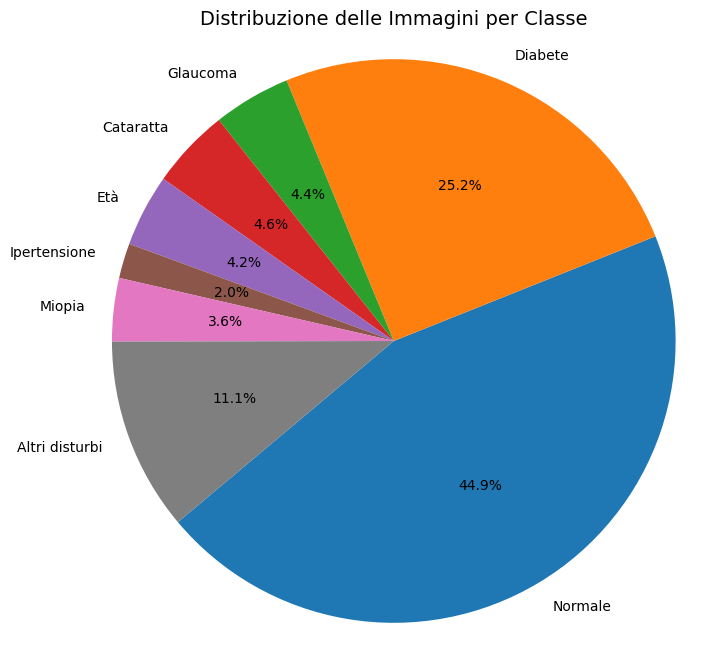

In [2]:
from tqdm import tqdm
import matplotlib.pyplot as plt

# Liste delle classi
classi = ["Normale", "Diabete", "Glaucoma", "Cataratta", "Età", "Ipertensione", "Miopia", "Altri disturbi"]

# Creazione dizionari per ciascuna classe
class_dict = {
    "N": [],
    "D": [],
    "G": [],
    "C": [],
    "A": [],
    "H": [],
    "M": [],
    "O": []
}

# Scorrere le righe della tabella e aggiungere filename e filepath dell'immagine
for _, row in tqdm(df.iterrows(), total=df.shape[0], desc="Caricamento dei path delle immagini"):
    image_path = os.path.join(image_dir, row['filename'])
    label = row['labels'].strip("[]").strip("'")  # Rimozione dei caratteri superflui
    if label in class_dict:
        class_dict[label].append({"filename": row['filename'], "image_path": image_path})

# Creare un dizionario con tutti i DataFrame
df_dict = {key: pd.DataFrame(class_dict[key]) for key in ["N", "D", "G", "C", "A", "H", "M", "O"]}

# Estrazione dei dati per il grafico
labels = classi
values = [len(df) for df in df_dict.values()]

# Stampa dei valori
print("Numero di immagini per ciascuna classe:")
for label, value in zip(labels, values):
    print(f"{label}: {value} immagini")

# Creazione del grafico a torta
plt.figure(figsize=(8, 8))
plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=220)
plt.title("Distribuzione delle Immagini per Classe", fontsize=14, fontweight='normal')

# Salvataggio del grafico come file immagine
plt.savefig('distribuzione_immagini_per_classe.png', format='jpg')

# Mostra il grafico
plt.axis('equal')
plt.show()

In [3]:
import cv2
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

# Funzione per leggere le immagini a colori RGB
def Load_RGB_image(image_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image

# Funzione per creare la maschera
def Mask_image(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  # Converti in scala di grigi

    mask = gray > 10  # Soglia per creare la maschera
    mask = binary_fill_holes(mask)  # Riempie i buchi

    # Operazione di apertura morfologica
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, kernel)

    return mask

# Funzione per estrarre valore intensità di colore su canale del rosso, verde e blu
def RGB_intensity(image):
    image_RGB = image
    R=[image_RGB[:,:,0]]
    G=[image_RGB[:,:,1]]
    B=[image_RGB[:,:,2]]

    R_ratio = np.sum(R) / (np.sum(R) + np.sum(G) + np.sum(B))
    G_ratio = np.sum(G) / (np.sum(R) + np.sum(G) + np.sum(B))
    B_ratio = np.sum(B) / (np.sum(R) + np.sum(G) + np.sum(B))

    return R_ratio, G_ratio, B_ratio

# Funzione per estrarre valori di tonalità (H), saturazione (S) e luminosità (V)
def calculate_HSV(image):
    image_HSV = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    H = [image_HSV[:,:,0]]
    S = [image_HSV[:,:,1]]
    V = [image_HSV[:,:,2]]

    H_ratio = np.sum(H) / (np.sum(H) + np.sum(S) + np.sum(V))
    S_ratio = np.sum(S) / (np.sum(H) + np.sum(S) + np.sum(V))
    V_ratio = np.sum(V) / (np.sum(H) + np.sum(S) + np.sum(V))

    return H_ratio, S_ratio, V_ratio

# Funzione per calcolare la GLCM e le features
def calculate_glcm_features(image, distances, angles, levels=256):
  image_gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) # Converti in scala di grigi

  # Calcola la GLCM
  glcm = graycomatrix(image_gray, distances=distances, angles=angles, levels=levels, symmetric=True, normed=True)
  features = {
        'contrast': graycoprops(glcm, 'contrast').mean(),
        'correlation': graycoprops(glcm, 'correlation').mean(),
        'energy': graycoprops(glcm, 'energy').mean(),
        'homogeneity': graycoprops(glcm, 'homogeneity').mean(),
        'entropy': calculate_glcm_entropy(glcm) # Uso funzione ausiliaria definita sotto
    }
  return features

def calculate_glcm_entropy(glcm):
    # Evita divisioni per zero e log di zero
    with np.errstate(divide='ignore', invalid='ignore'):
        entropy = -np.sum(glcm * np.log2(glcm + 1e-10))  # Aggiungo un piccolo valore per evitare log(0)
    return entropy


<ipython-input-4-09329b873b09>:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


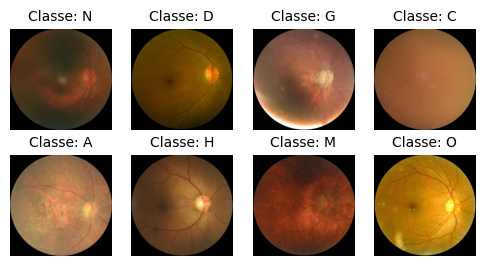

<ipython-input-4-09329b873b09>:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


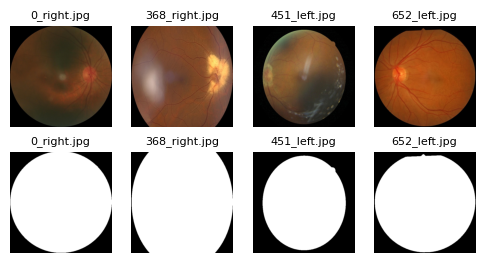

In [4]:
import os
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes

# Stampa un'immagine per ogni classe
fig, axes = plt.subplots(2, 4, figsize=(6, 3), gridspec_kw={'hspace': 0.2, 'wspace': 0.2})
dfs = list(df_dict.items())

for fig_index in range(2):
    for i in range(4):
        index = fig_index * 4 + i
        key, df = dfs[index]

        image_path = df.iloc[0]['image_path']
        image = Load_RGB_image(image_path)

        axes[fig_index, i].imshow(image)
        axes[fig_index, i].axis('off')
        axes[fig_index, i].set_title(f"Classe: {key}", fontsize=10)

plt.tight_layout()
plt.savefig('immagine_finale.jpg', format='jpg', dpi=300)
plt.show()

# Stampa maschere delle immagini
fig, axes = plt.subplots(2, 4, figsize=(6, 3), gridspec_kw={'hspace': 0.2, 'wspace': 0.2})  # Ridotta hspace
image_files = ["0_right.jpg", "368_right.jpg", "451_left.jpg", "652_left.jpg"]

for col, c in enumerate(image_files):
    image_path = os.path.join(image_dir, c)
    image = Load_RGB_image(image_path)
    mask = Mask_image(image)

    axes[0, col].imshow(image)
    axes[0, col].axis('off')
    axes[0, col].set_title(f"{c}", fontsize=8)

    axes[1, col].imshow(mask, cmap='gray')
    axes[1, col].axis('off')
    axes[1, col].set_title(f"{c}", fontsize=8)

plt.tight_layout()
plt.savefig('maschera_finale.jpg', format='jpg', dpi=300)
plt.show()






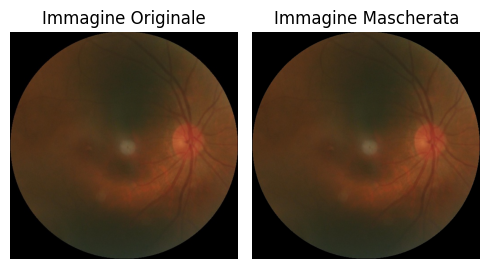

In [5]:
# Controllo nella creazione della maschera

# Path dell'immagine da controllare
image_path = os.path.join(image_dir, "0_right.jpg")

# Carico immagine
image = Load_RGB_image(image_path)

# Maschera
mask = Mask_image(image)

# Applicare la maschera
image_masked = image * mask[..., np.newaxis]  # La maschera viene applicata su tutti i canali (RGB)

# Visualizza l'immagine originale e l'immagine mascherata
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

axes[0].imshow(image)
axes[0].set_title('Immagine Originale')
axes[0].axis('off')

axes[1].imshow(image_masked)
axes[1].set_title('Immagine Mascherata')
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [6]:
for df in df_dict.values():
    # Aggiungi tutte le colonne necessarie per le features
    df['R_ratio'] = np.nan
    df['G_ratio'] = np.nan
    df['B_ratio'] = np.nan
    df['H_ratio'] = np.nan
    df['S_ratio'] = np.nan
    df['V_ratio'] = np.nan
    # Feature GLCM per angoli (0°, pi/4, pi/2, 3*pi/4)
    for angolo in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
        angolo_str = {
            0: "0",
            np.pi/4: "pi/4",
            np.pi/2: "pi/2",
            3*np.pi/4: "3pi/4"
        }[angolo]

        df[f'glcm_contrast_{angolo_str}'] = np.nan
        df[f'glcm_correlation_{angolo_str}'] = np.nan
        df[f'glcm_energy_{angolo_str}'] = np.nan
        df[f'glcm_homogeneity_{angolo_str}'] = np.nan
        df[f'glcm_entropy_{angolo_str}'] = np.nan

    # Ciclo sulle righe del DataFrame per calcolare le feature
    for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Calcolo delle feature"):
        image_path = row['image_path']

        # Carica l'immagine
        image = Load_RGB_image(image_path)

        # Maschera dell'immagine
        mask = Mask_image(image)

        # Applicare la maschera sull'immagine
        image_masked = image * mask[..., np.newaxis]  # Aggiunge un canale extra per RGB (3 canali)

        # Calcola le feature di intensità RGB sull'immagine mascherata
        R_ratio, G_ratio, B_ratio = RGB_intensity(image_masked)

        # Calcola le feature HSV sull'immagine mascherata
        H_ratio, S_ratio, V_ratio = calculate_HSV(image_masked)

        # Aggiorna il DataFrame con i valori delle feature
        df.loc[index, ['R_ratio', 'G_ratio', 'B_ratio']] = R_ratio, G_ratio, B_ratio
        df.loc[index, ['H_ratio', 'S_ratio', 'V_ratio']] = H_ratio, S_ratio, V_ratio

        # Calcola le feature GLCM per ogni angolo sull'immagine mascherata
        for angolo in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
            angolo_str = {
                0: "0",
                np.pi/4: "pi/4",
                np.pi/2: "pi/2",
                3*np.pi/4: "3pi/4"
            }[angolo]

            glcm_features = calculate_glcm_features(image_masked, distances=[1], angles=[angolo])

            # Aggiorna il DataFrame con i valori delle feature GLCM
            df.loc[index, f'glcm_contrast_{angolo_str}'] = glcm_features['contrast']
            df.loc[index, f'glcm_correlation_{angolo_str}'] = glcm_features['correlation']
            df.loc[index, f'glcm_energy_{angolo_str}'] = glcm_features['energy']
            df.loc[index, f'glcm_homogeneity_{angolo_str}'] = glcm_features['homogeneity']
            df.loc[index, f'glcm_entropy_{angolo_str}'] = glcm_features['entropy']

# Stampa i primi valori per verificare
print(df_dict['N'].head())
# Salva i DataFrame con le feature in file CSV
df_dict['N'].to_csv("df_N_features.csv", index=True)
df_dict['D'].to_csv("df_D_features.csv", index=True)
df_dict['G'].to_csv("df_G_features.csv", index=True)
df_dict['C'].to_csv("df_C_features.csv", index=True)
df_dict['A'].to_csv("df_A_features.csv", index=True)
df_dict['H'].to_csv("df_H_features.csv", index=True)
df_dict['M'].to_csv("df_M_features.csv", index=True)
df_dict['O'].to_csv("df_O_features.csv", index=True)

Calcolo delle feature: 100%|██████████| 708/708 [00:40<00:00, 17.29it/s]


       filename                                         image_path   R_ratio  \
0   0_right.jpg  /root/.cache/kagglehub/datasets/andrewmvd/ocul...  0.491542   
1   1_right.jpg  /root/.cache/kagglehub/datasets/andrewmvd/ocul...  0.467782   
2   8_right.jpg  /root/.cache/kagglehub/datasets/andrewmvd/ocul...  0.590516   
3  10_right.jpg  /root/.cache/kagglehub/datasets/andrewmvd/ocul...  0.501889   
4  29_right.jpg  /root/.cache/kagglehub/datasets/andrewmvd/ocul...  0.441741   

    G_ratio   B_ratio   H_ratio   S_ratio   V_ratio  glcm_contrast_0  \
0  0.328957  0.179502  0.067128  0.614113  0.318758        16.635637   
1  0.328312  0.203906  0.042875  0.442416  0.514709        46.446436   
2  0.258641  0.150843  0.020451  0.528726  0.450823        32.817457   
3  0.297771  0.200339  0.029940  0.446009  0.524051        71.723486   
4  0.334925  0.223334  0.062839  0.524609  0.412552        44.434473   

   glcm_correlation_0  ...  glcm_contrast_pi/2  glcm_correlation_pi/2  \
0            

In [19]:
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import lilliefors
from tqdm import tqdm

# Dizionario per salvare i risultati del test di Lilliefors
lilliefors_results_dict = {}
Non_norm = 0
Norm = 0
# Loop su ogni classe nel dizionario
for class_name, df in df_dict.items():
    print(f"Eseguendo il test di Lilliefors per la classe: {class_name}")

    # Rimuove colonne non numeriche
    numeric_df = df.select_dtypes(include=[np.number]).copy()

    # Liste per salvare statistiche e p-value
    stat_results = []
    p_values = []
    normalità = []
    feature_names = numeric_df.columns  # Nomi delle features numeriche
    # Loop sulle feature numeriche
    for feature in tqdm(feature_names, desc=f"Test su classe {class_name}"):

        # Rimuove NaN prima del test
        data = numeric_df[feature].dropna().values

        # Test di Lilliefors
        stat, p_value = lilliefors(data)
        stat_results.append(stat)
        p_values.append(p_value)
        if p_value < 0.05:
            normalità.append("No")
            Non_norm += 1
        else:
            normalità.append("Si")
            Norm += 1

    # Creazione DataFrame con i risultati
    results_df = pd.DataFrame({
        "Feature": feature_names,
        "Stat": stat_results,
        "P-Value": p_values,
        "Normalità": normalità
    })

    # Salva nel dizionario
    lilliefors_results_dict[class_name] = results_df

    # Salva in un file CSV
    results_df.to_csv(f"lilliefors_results_{class_name}.csv", index=False)

print(f"distribuzioni non normali", Non_norm)
print(f"distribuzioni normali", Norm)
# Visualizza i risultati
for class_name, df in df_dict.items():
    print("---------------------------------------------------------------------")
    print(f"Stampa dei risultati per la classe: {class_name}")
    print(lilliefors_results_dict[class_name])



Eseguendo il test di Lilliefors per la classe: N


Test su classe N: 100%|██████████| 26/26 [00:00<00:00, 740.43it/s]


Eseguendo il test di Lilliefors per la classe: D


Test su classe D: 100%|██████████| 26/26 [00:00<00:00, 860.73it/s]


Eseguendo il test di Lilliefors per la classe: G


Test su classe G: 100%|██████████| 26/26 [00:00<00:00, 775.99it/s]


... (7 outputs left out)

Test su classe M: 100%|██████████| 26/26 [00:00<00:00, 716.36it/s]


Eseguendo il test di Lilliefors per la classe: O


Test su classe O: 100%|██████████| 26/26 [00:00<00:00, 697.74it/s]


distribuzioni non normali 159
distribuzioni normali 49
---------------------------------------------------------------------
Stampa dei risultati per la classe: N
                   Feature      Stat   P-Value Normalità
0                  R_ratio  0.087833  0.001000        No
1                  G_ratio  0.069900  0.001000        No
2                  B_ratio  0.076413  0.001000        No
3                  H_ratio  0.184373  0.001000        No
4                  S_ratio  0.019055  0.015378        No
5                  V_ratio  0.019642  0.009807        No
6          glcm_contrast_0  0.115088  0.001000        No
7       glcm_correlation_0  0.134150  0.001000        No
8            glcm_energy_0  0.279489  0.001000        No
9       glcm_homogeneity_0  0.022044  0.002194        No
10          glcm_entropy_0  0.041201  0.001000        No
11      glcm_contrast_pi/4  0.119536  0.001000        No
12   glcm_correlation_pi/4  0.085579  0.001000        No
13        glcm_energy_pi/4  0.278770  0

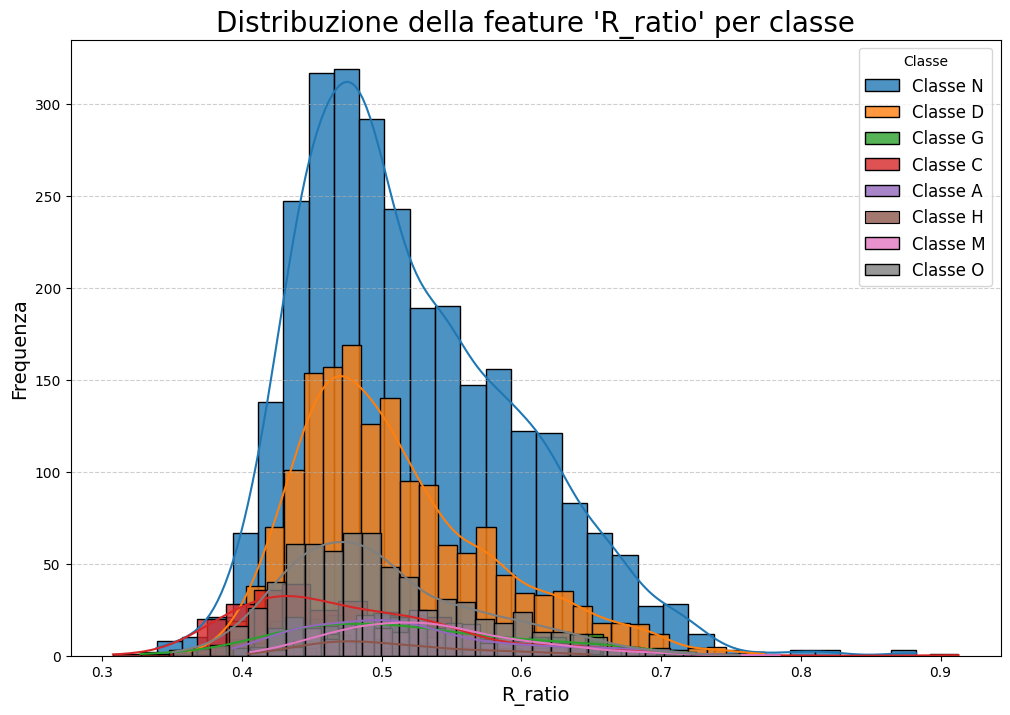

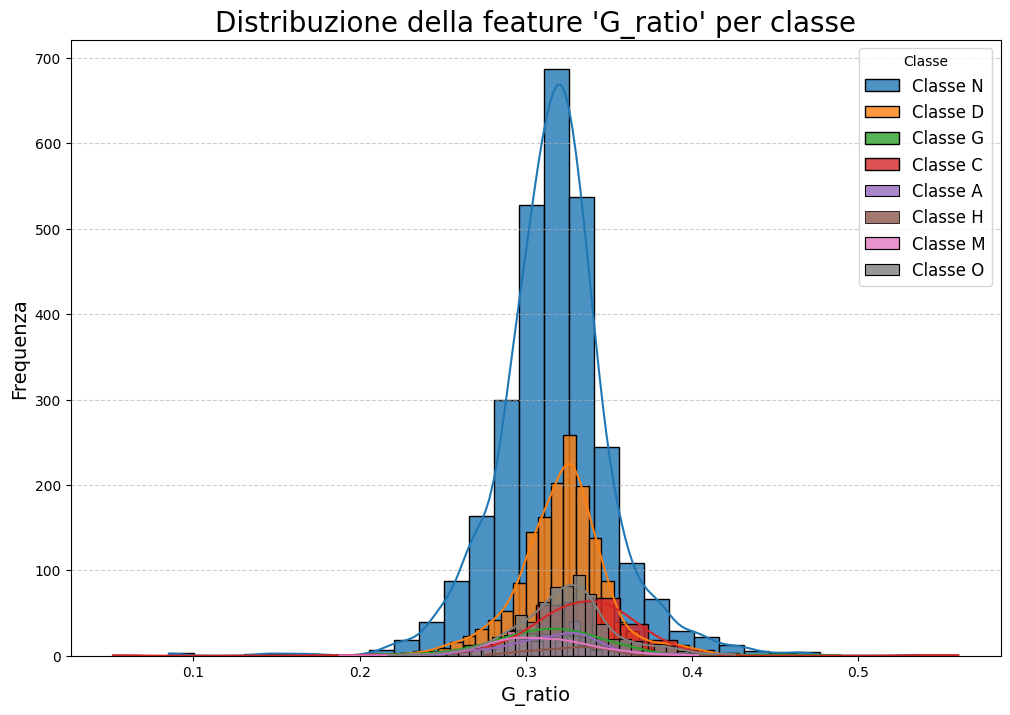

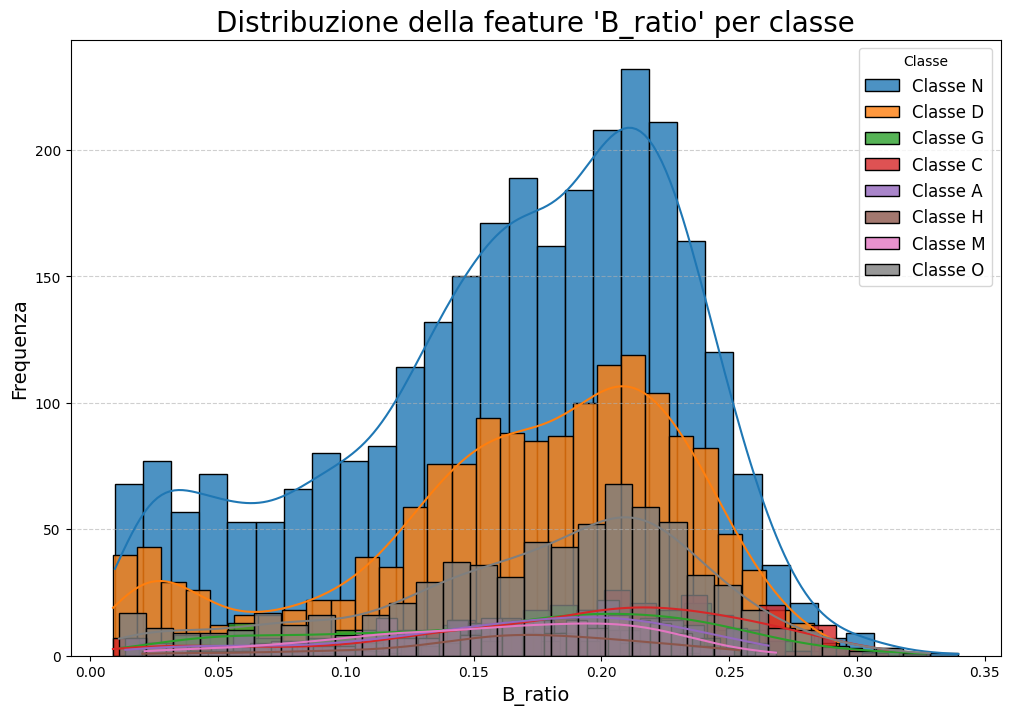

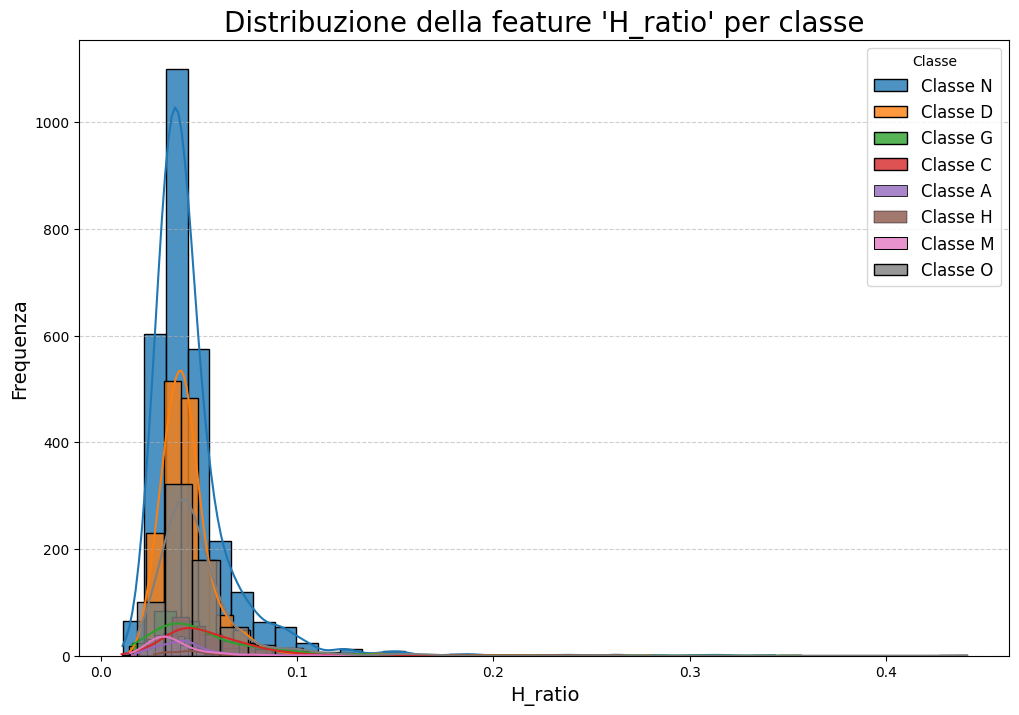

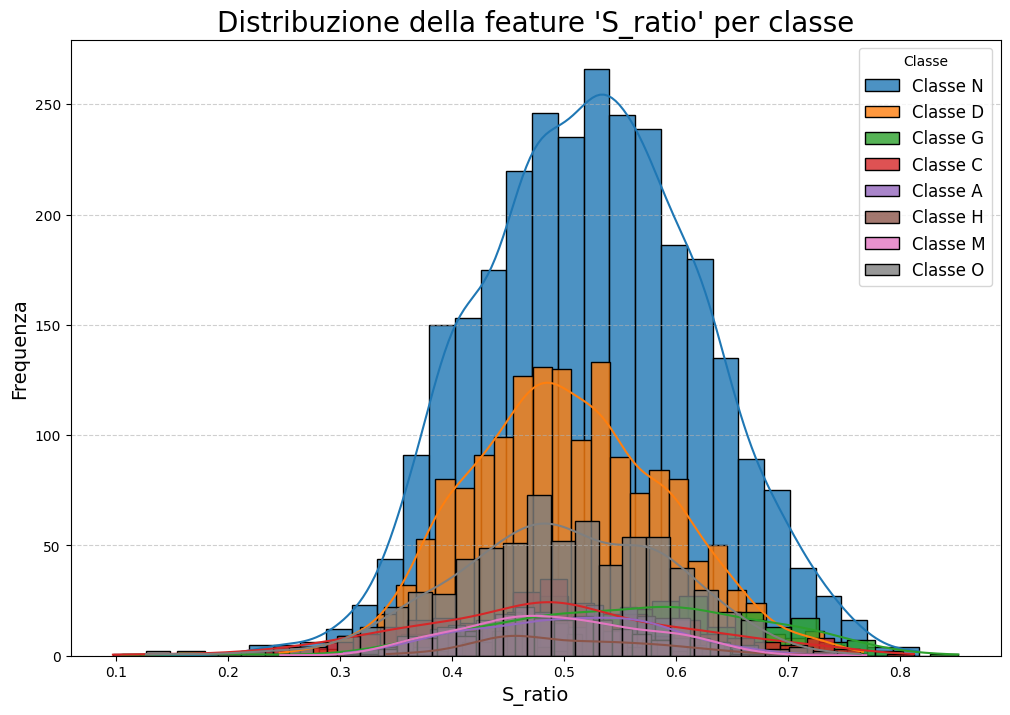

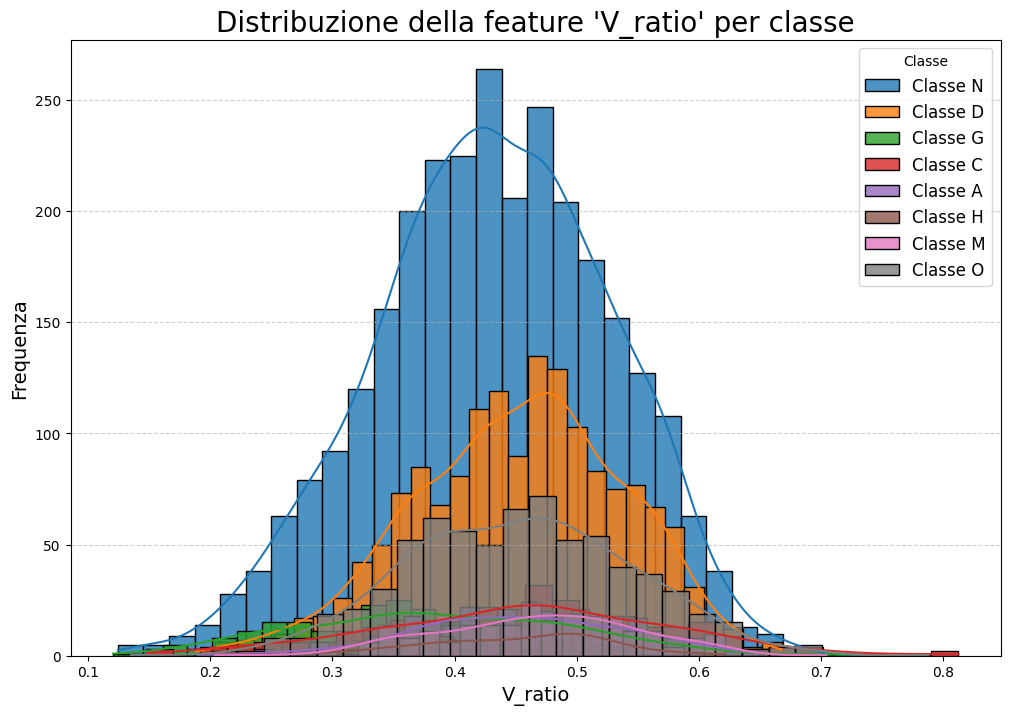

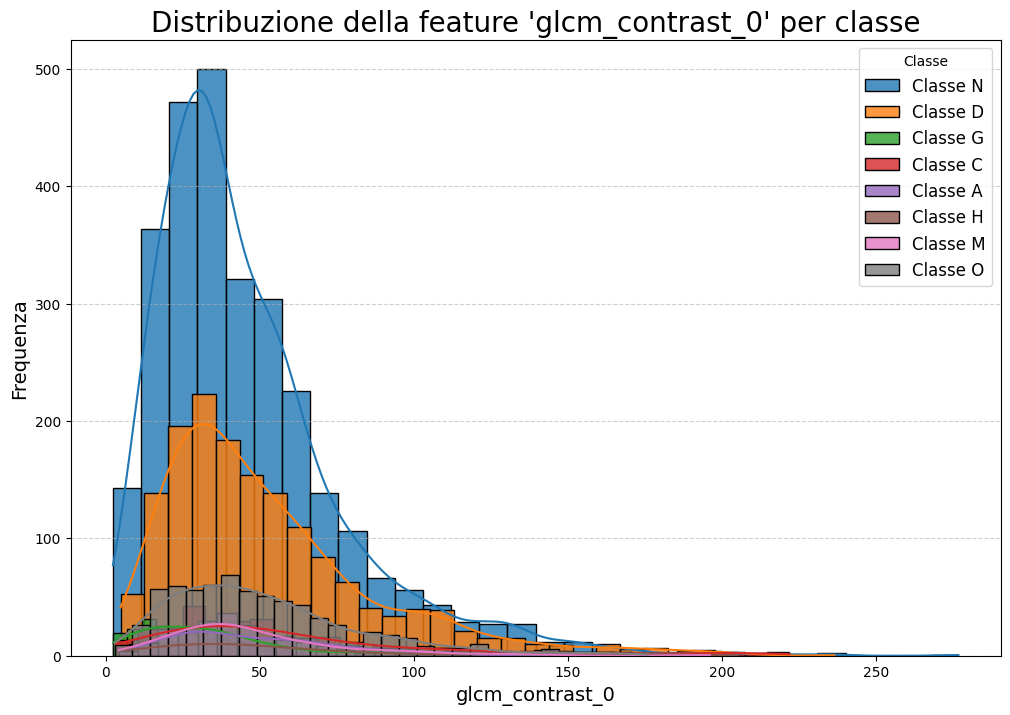

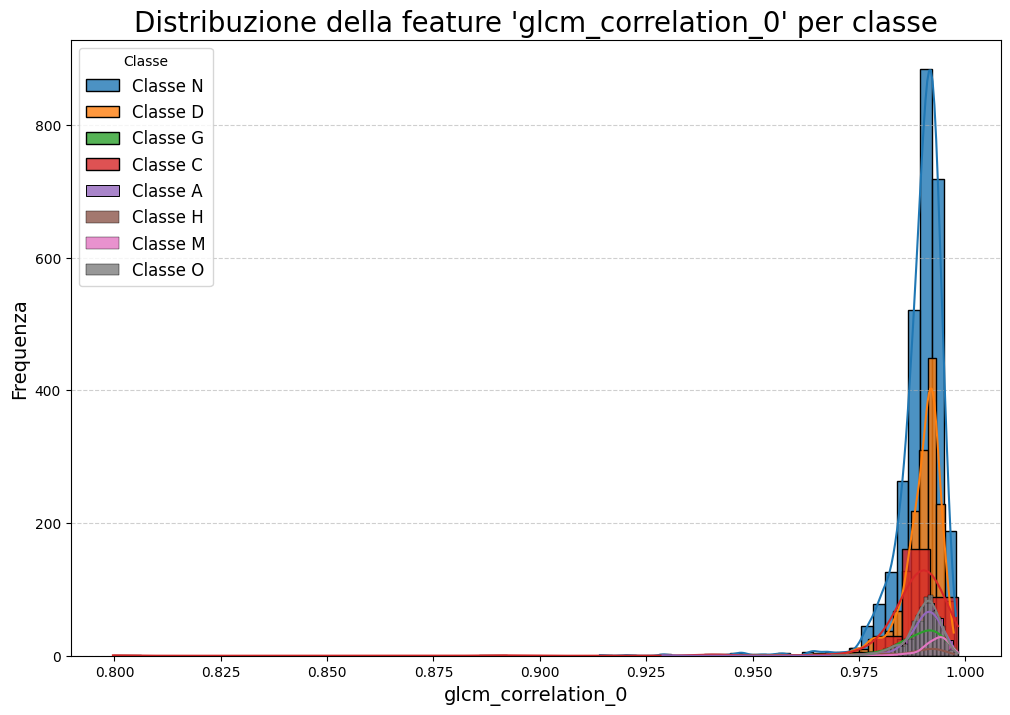

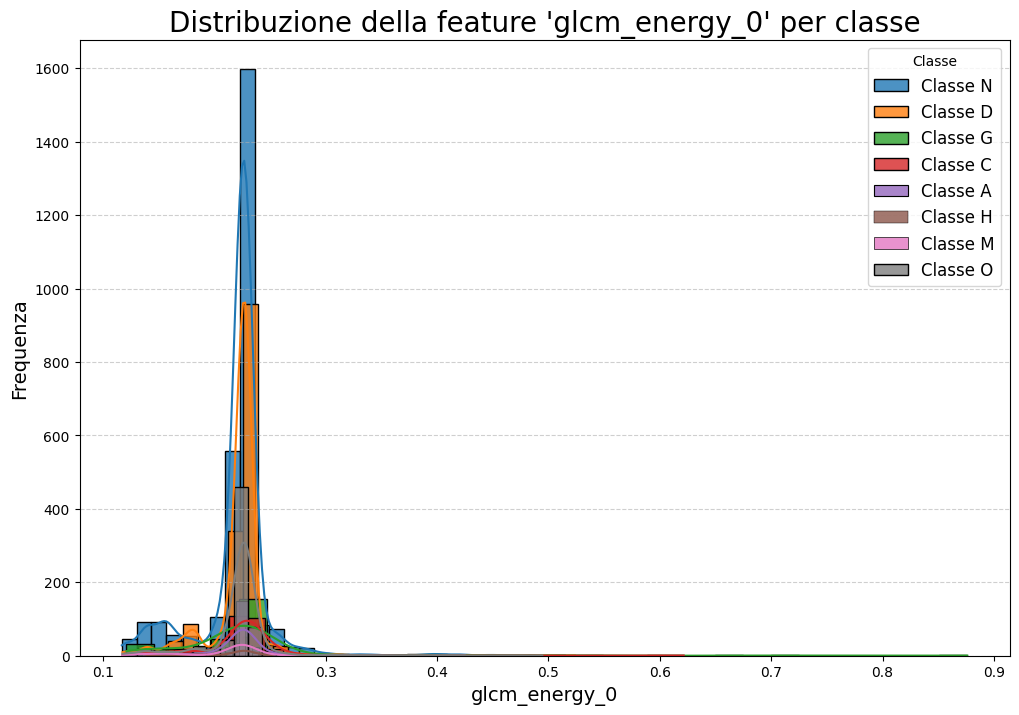

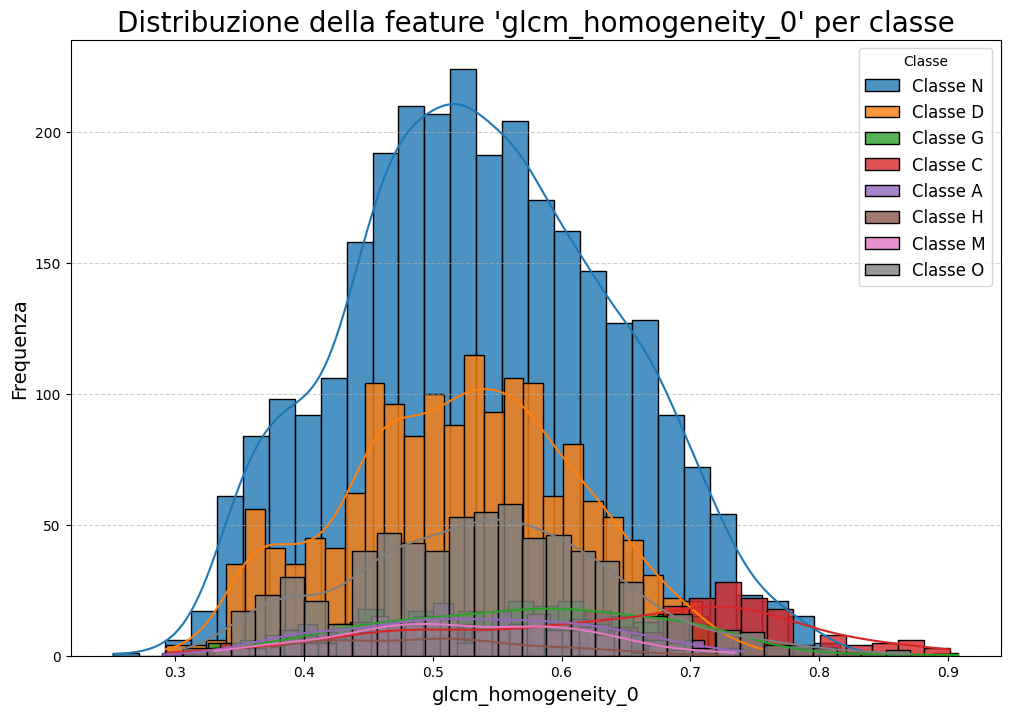

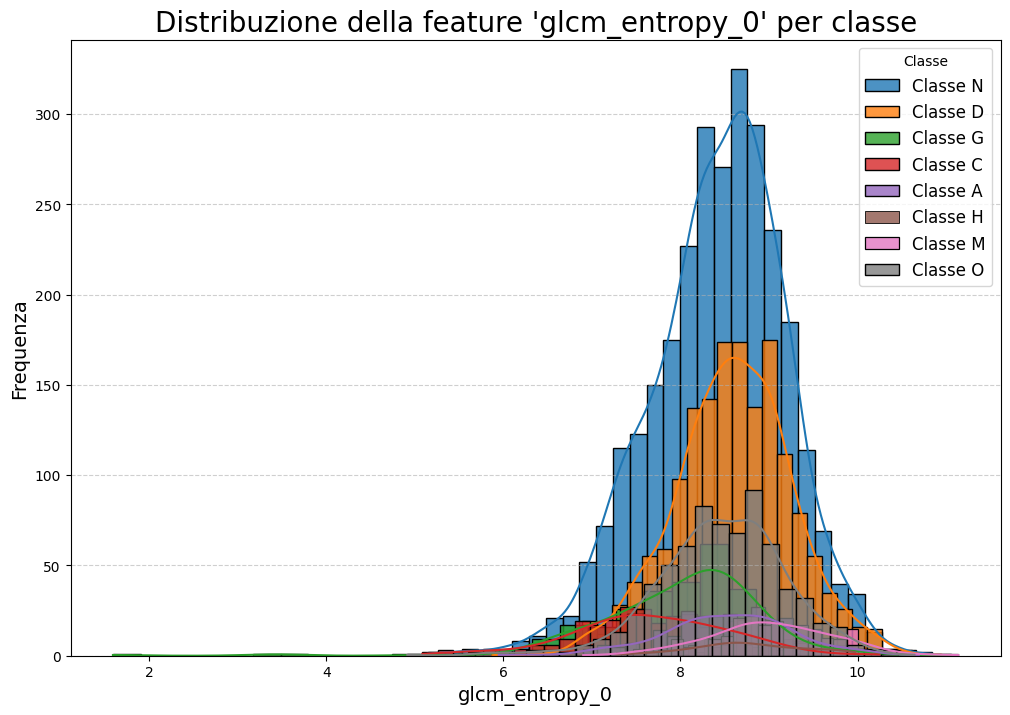

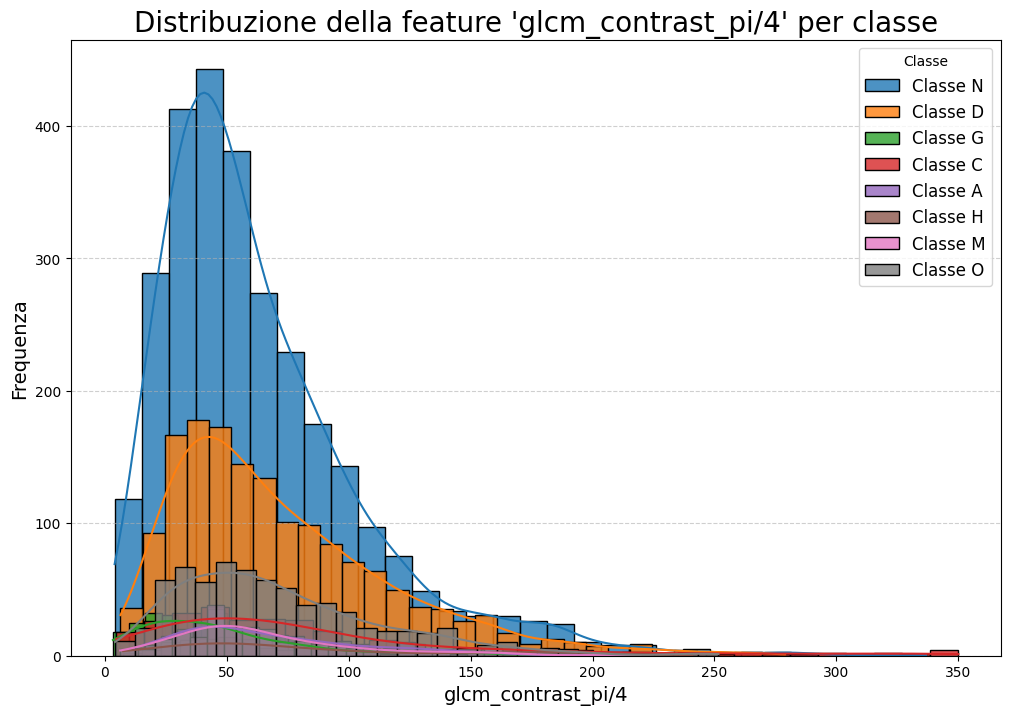

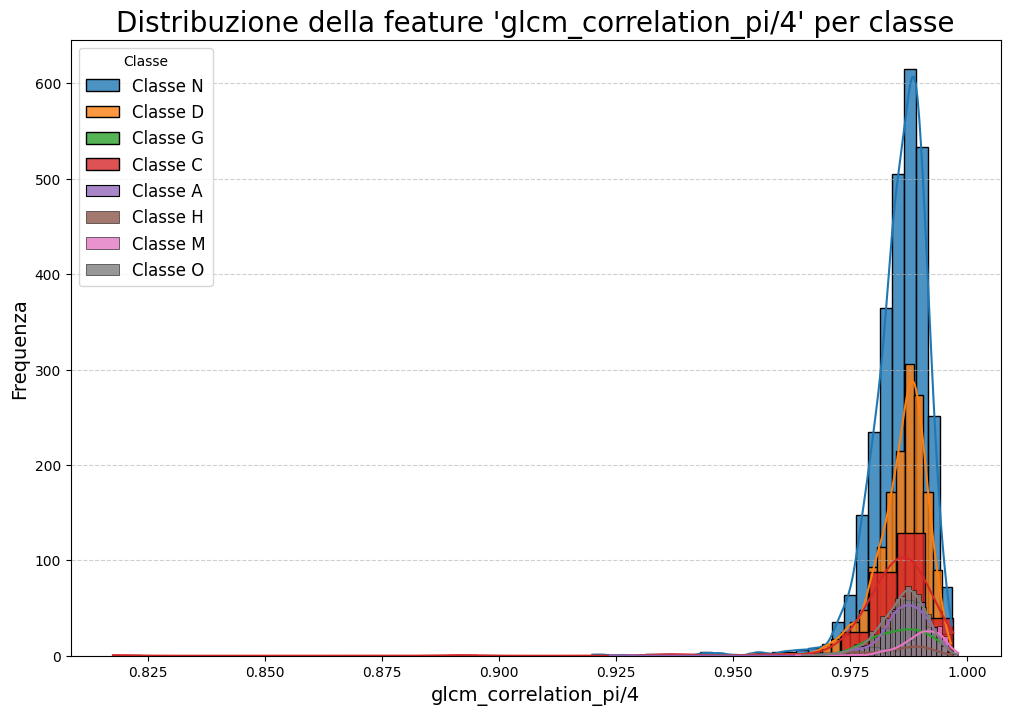

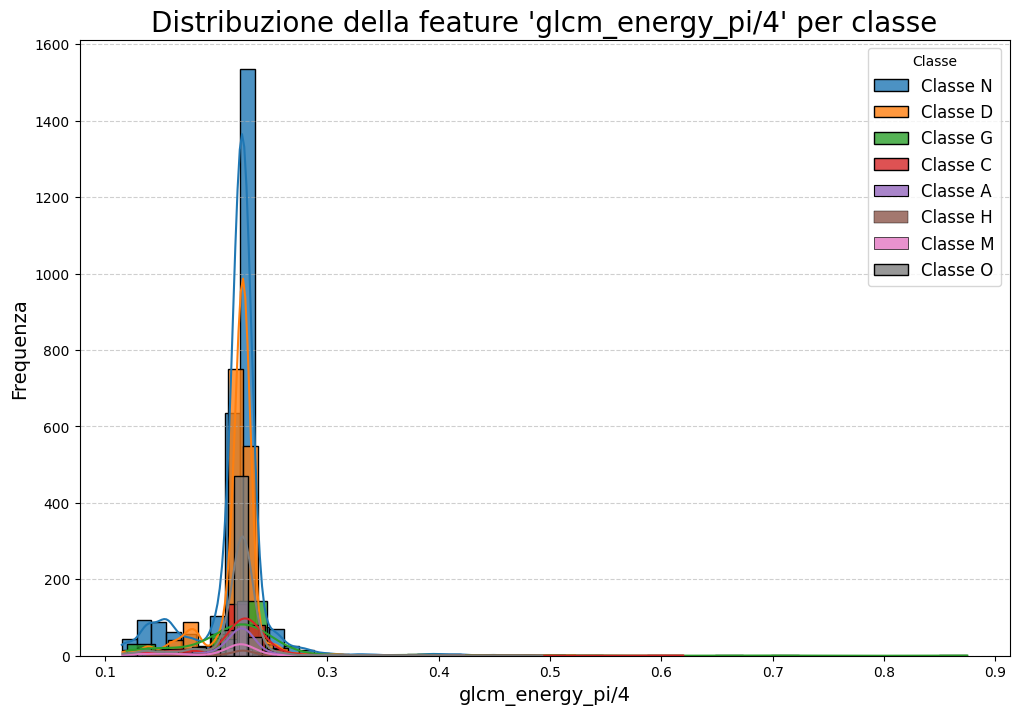

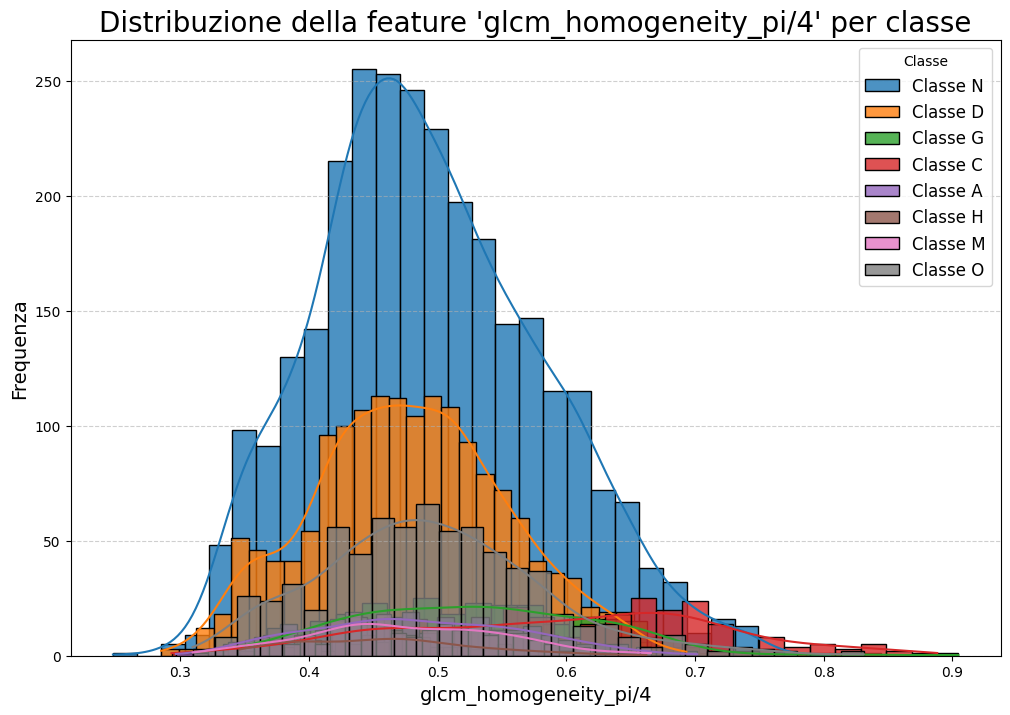

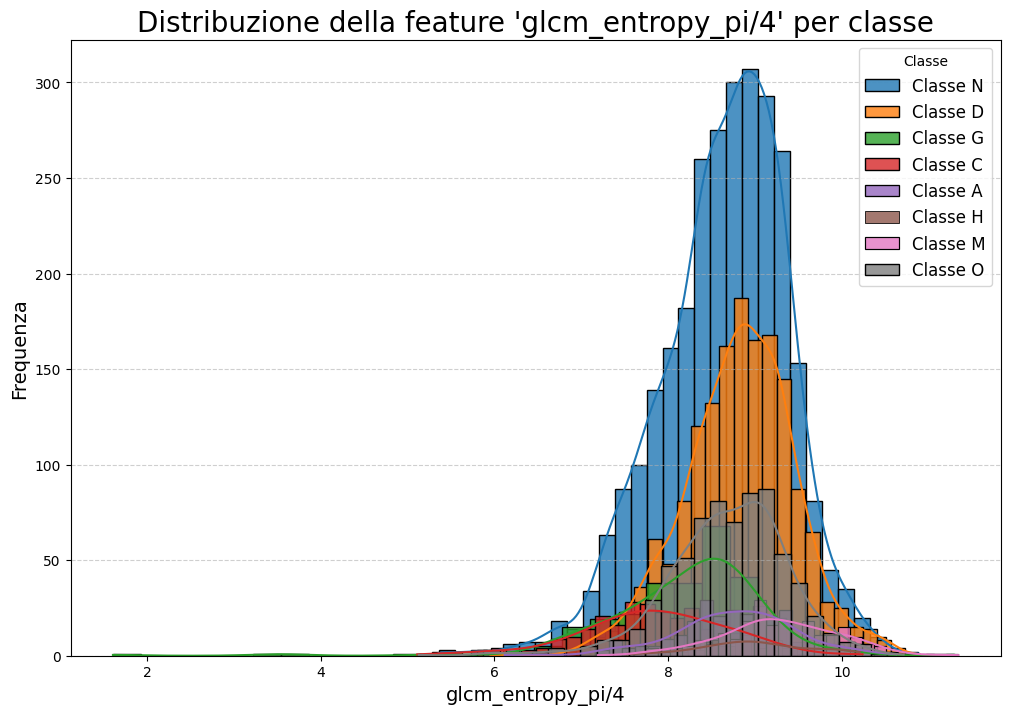

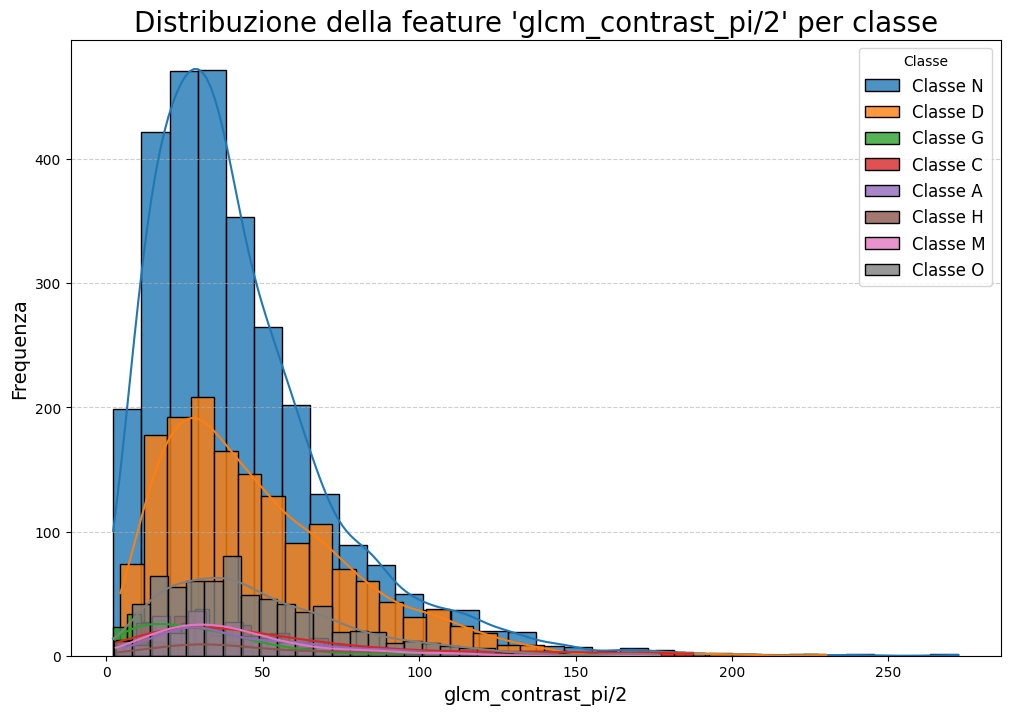

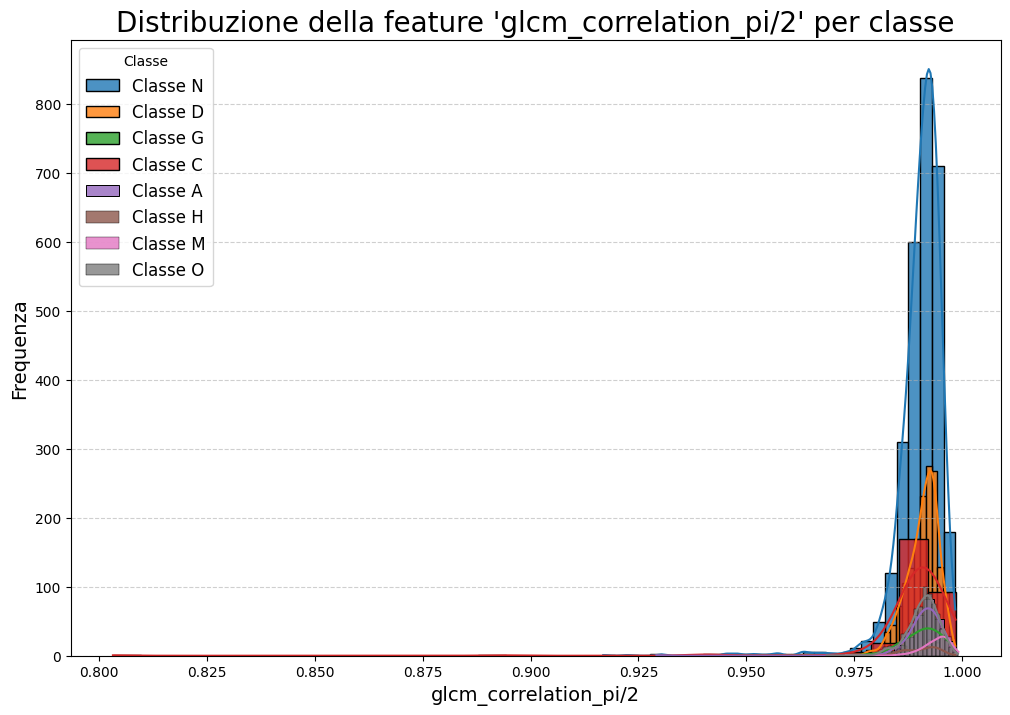

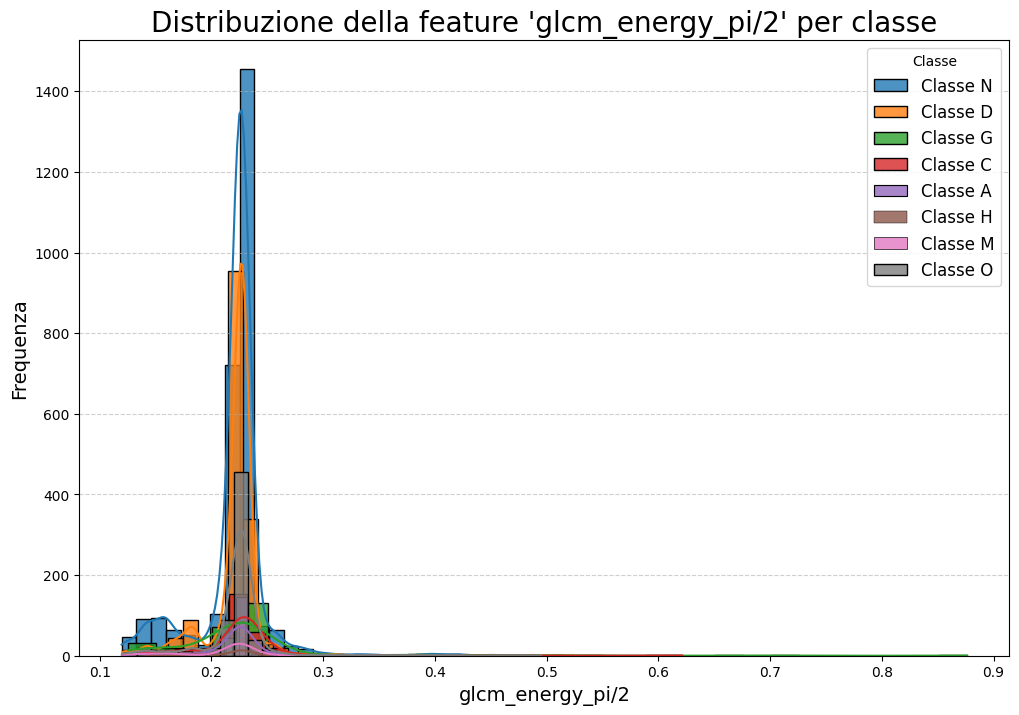

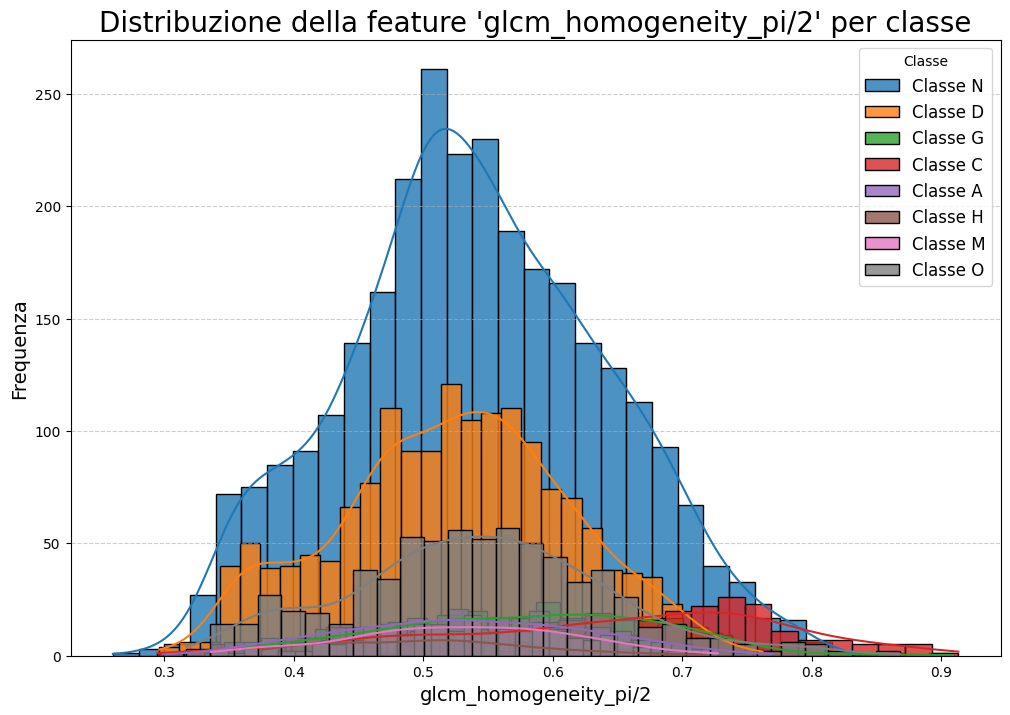

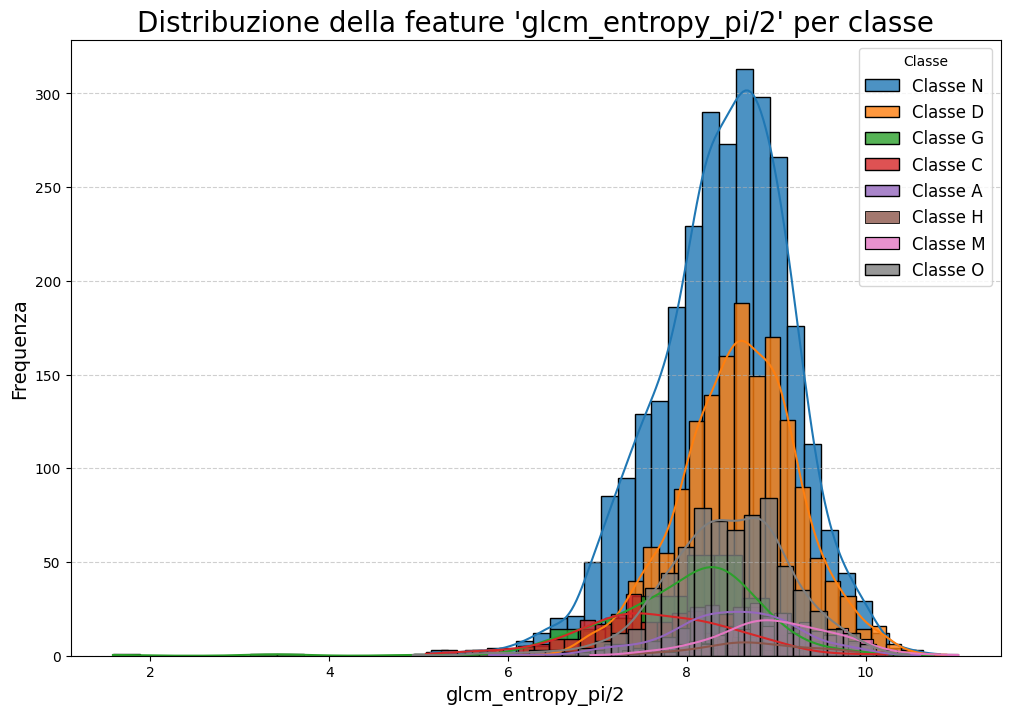

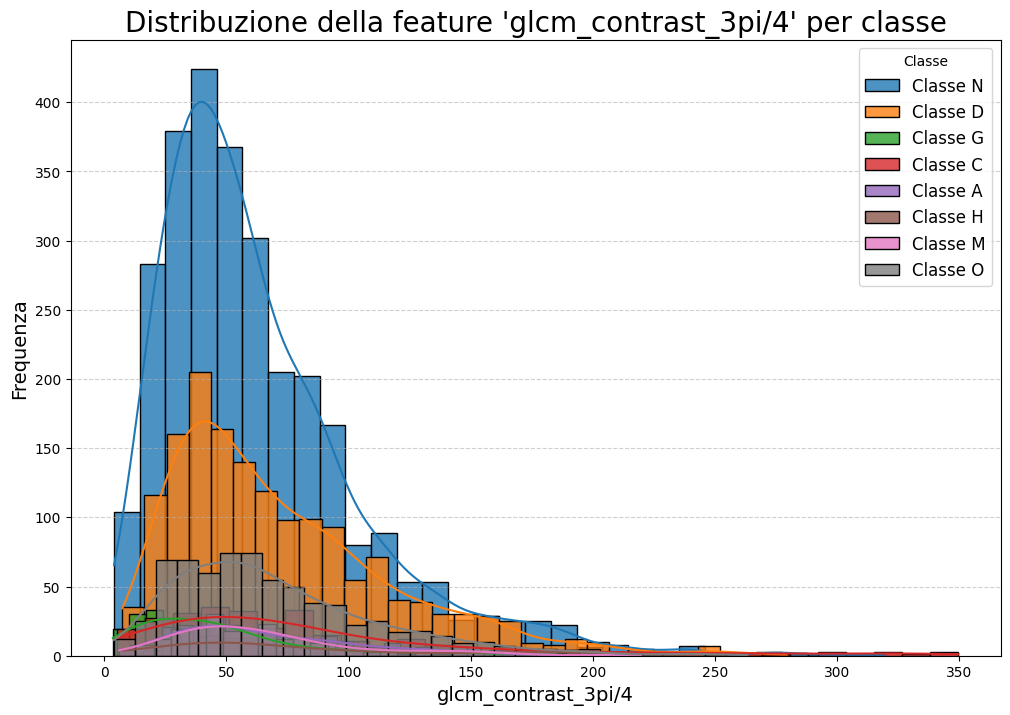

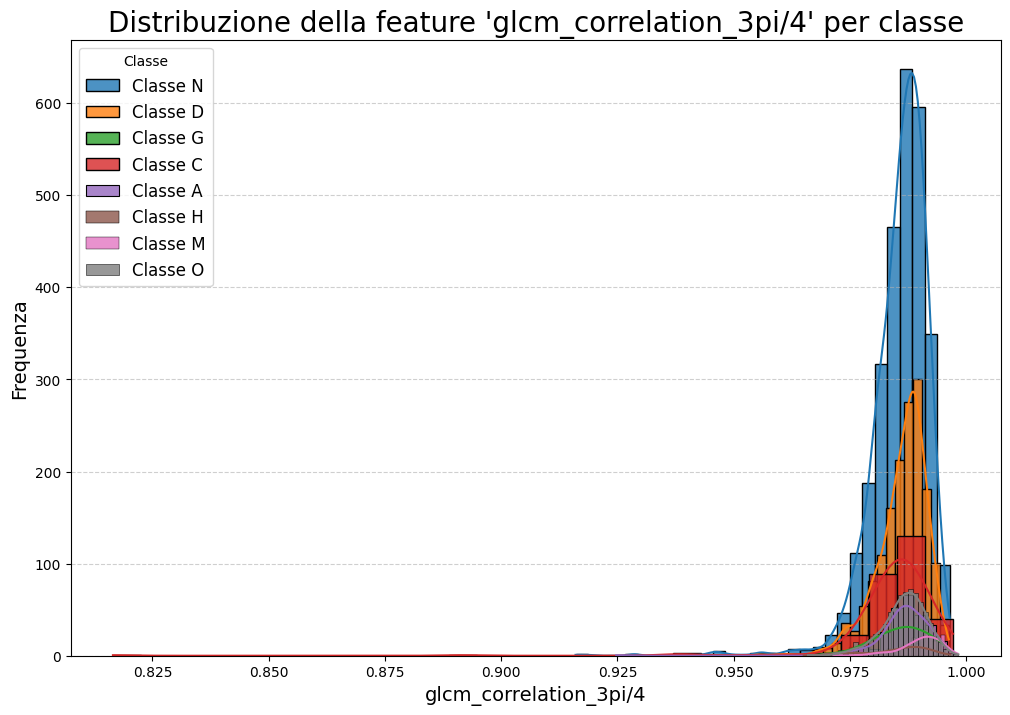

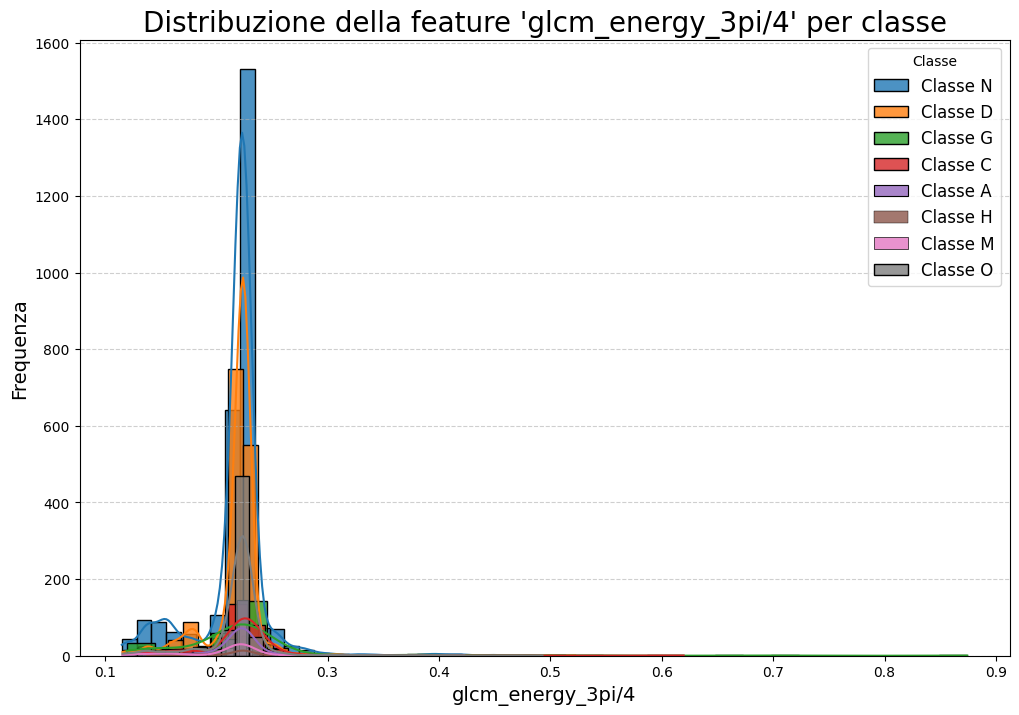

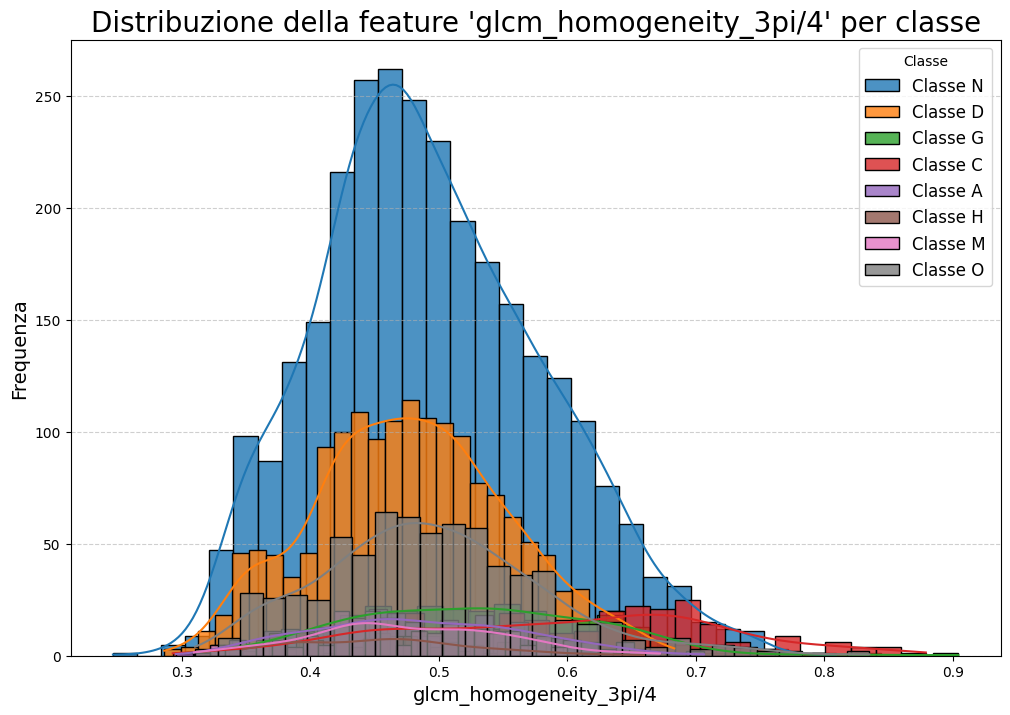

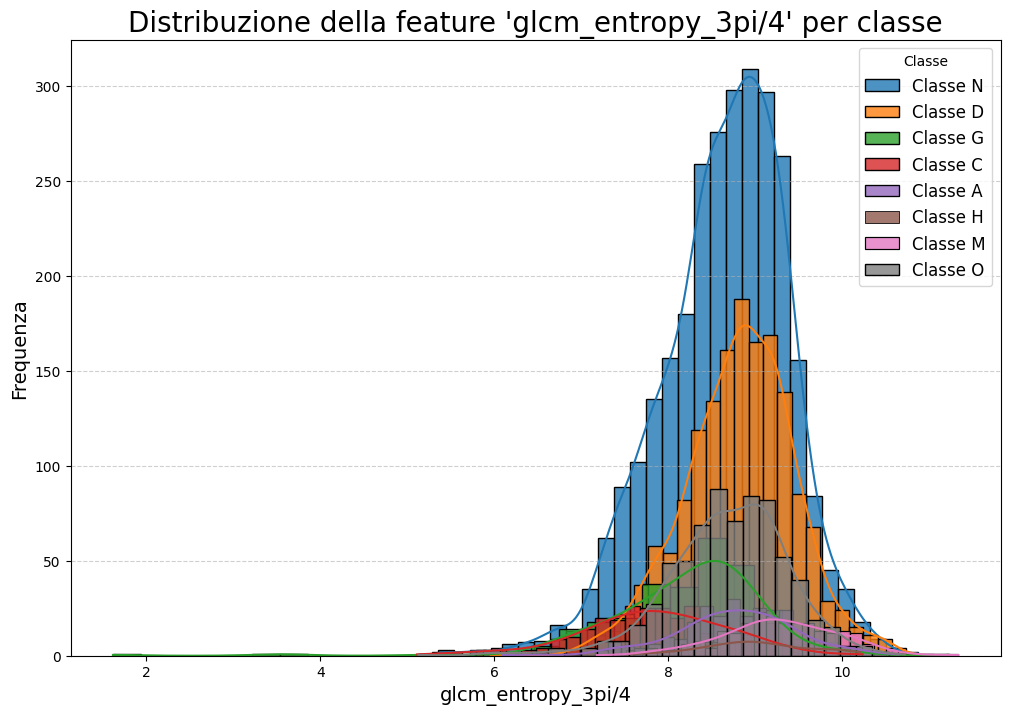

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import re

# Creazione degli istogrammi per ogni feature
for feature in feature_names:
    plt.figure(figsize=(12, 8))  # Imposta la dimensione della figura
    for class_name, class_df in df_dict.items():
        # Estrai i dati per la feature attuale per la classe corrente
        class_data = class_df[feature]
        sns.histplot(
            class_data,
            kde=True,
            bins=30,
            label=f"Classe {class_name}",
            alpha=0.8,
        )

    # Aggiunge titolo e etichette
    plt.title(f"Distribuzione della feature '{feature}' per classe", fontsize=20)
    plt.xlabel(feature, fontsize=14)
    plt.ylabel("Frequenza", fontsize=14)
    plt.legend(title="Classe", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    safe_feature_name = re.sub(r"[^\w\-_]", "_", feature)  # Pulizia del nome della feature per caratteri non validi nel nome del file

    # Salvataggio dell'immagine
    plt.savefig(f"Distribuzione_della_feature_{safe_feature_name}_per_classe.png", dpi=300, bbox_inches="tight")

    # Mostra il grafico
    plt.show()
    plt.close()


In [9]:
import scipy.stats as stats

results = []
alpha = 0.05  # Livello di significatività

# Iteriamo su ogni feature
for feature in feature_names:
    group_data = [df[feature] for df in df_dict.values()]

    # Calcoliamo il test di Kruskal-Wallis
    stat, p_value = stats.kruskal(*group_data)

    if p_value < alpha:
      significative = "SI"
    else:
      significative = "NO"

    # Salviamo i risultati in una lista
    results.append({"Feature": feature, "Stat": stat, "P-Value": p_value, "Significative": significative})

# Creiamo un DataFrame con i risultati
df_KW = pd.DataFrame(results)
df_KW.to_csv(f"Risultati test Kruskal-Wallis.csv", index=False)
print(df_KW)


                   Feature        Stat        P-Value Significative
0                  R_ratio  137.950652   1.365682e-26            SI
1                  G_ratio  189.031266   2.404814e-37            SI
2                  B_ratio   60.635955   1.126720e-10            SI
3                  H_ratio  208.898582   1.494018e-41            SI
4                  S_ratio  140.798560   3.457801e-27            SI
5                  V_ratio  169.077579   3.928379e-33            SI
6          glcm_contrast_0  143.264513   1.051741e-27            SI
7       glcm_correlation_0  160.411058   2.628409e-31            SI
8            glcm_energy_0   68.238811   3.350333e-12            SI
9       glcm_homogeneity_0  250.461612   2.209736e-50            SI
10          glcm_entropy_0  486.720355  5.734971e-101            SI
11      glcm_contrast_pi/4  153.804831   6.443788e-30            SI
12   glcm_correlation_pi/4  181.172652   1.101428e-35            SI
13        glcm_energy_pi/4   66.234375   8.49084

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


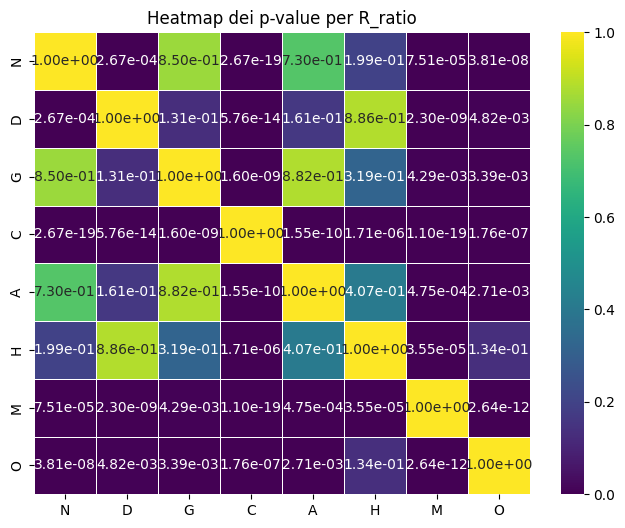

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


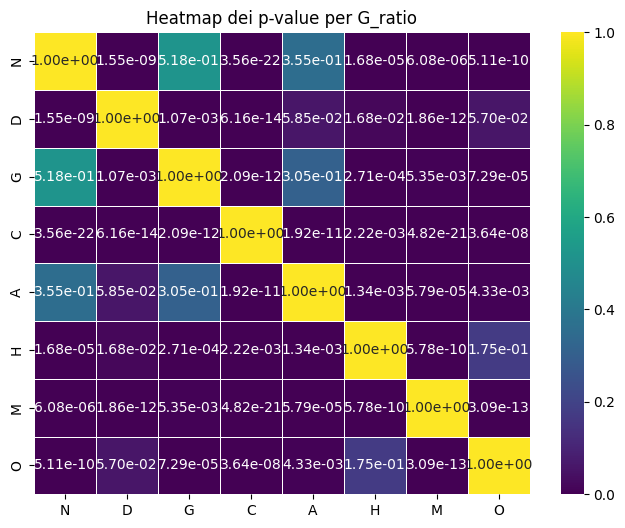

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


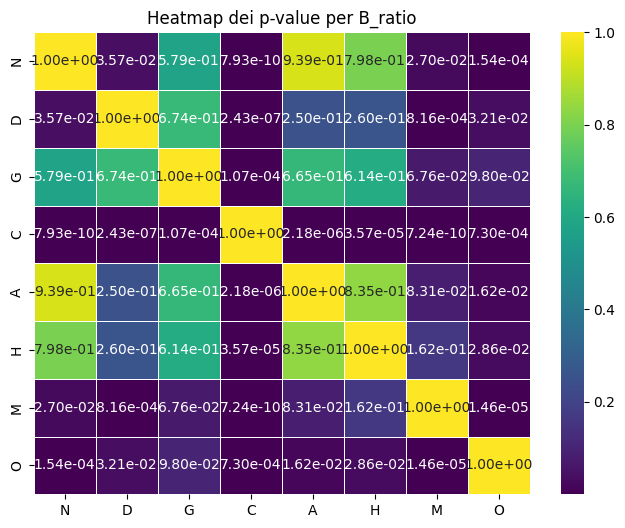

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


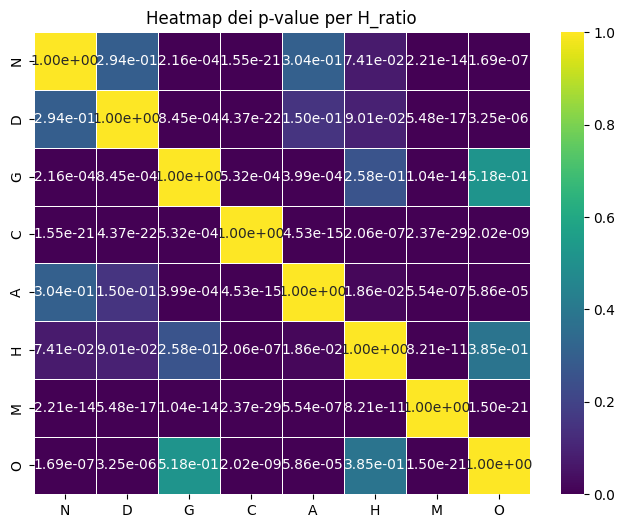

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


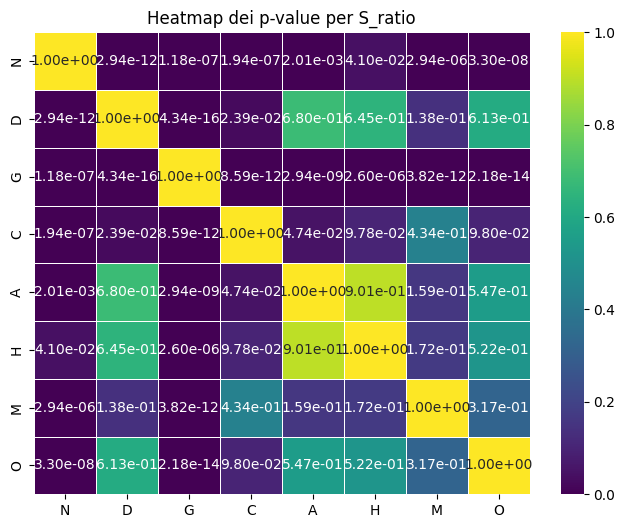

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


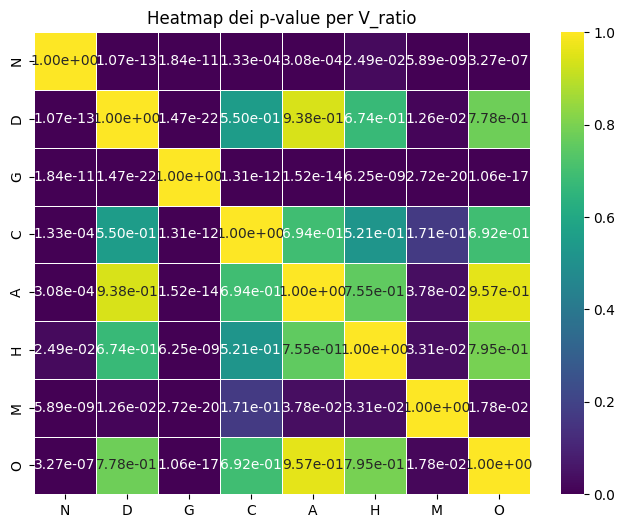

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


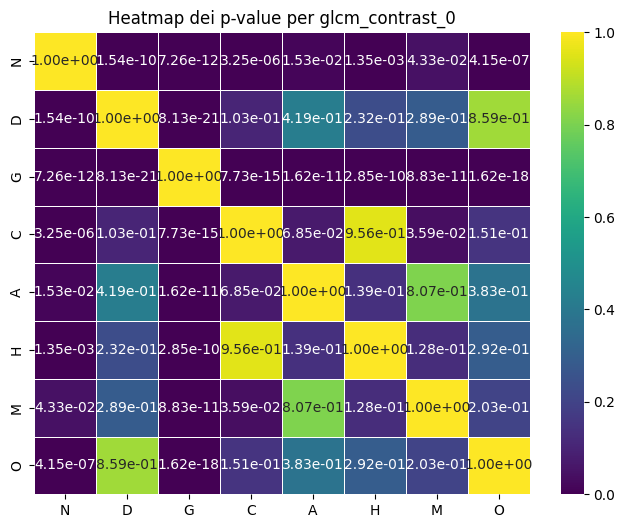

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


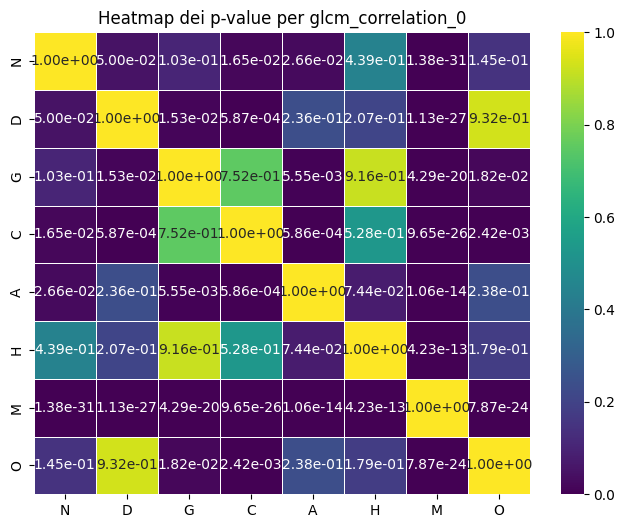

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


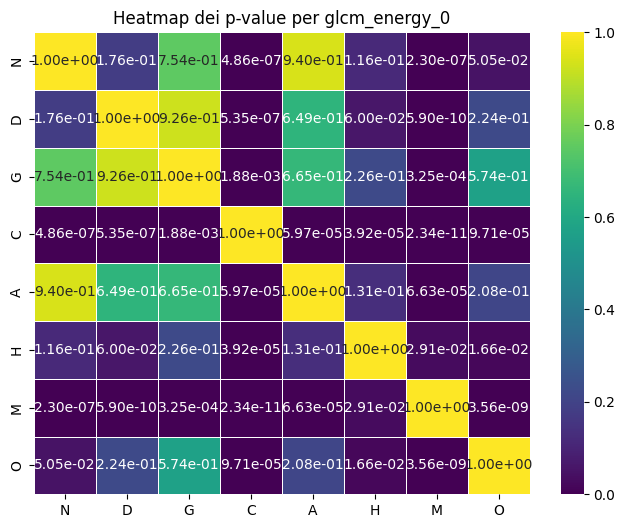

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


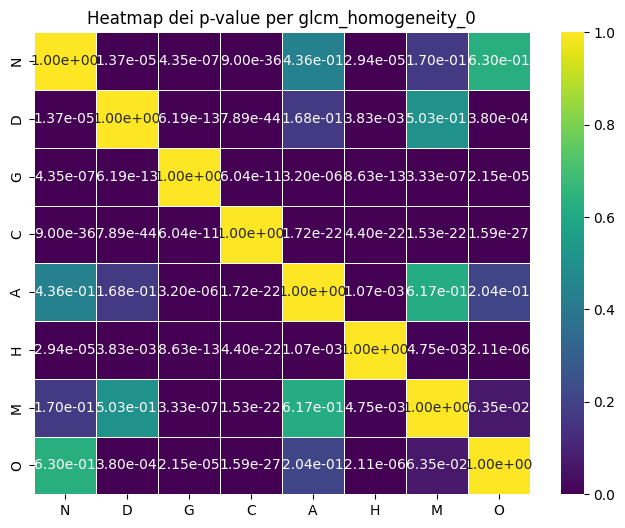

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


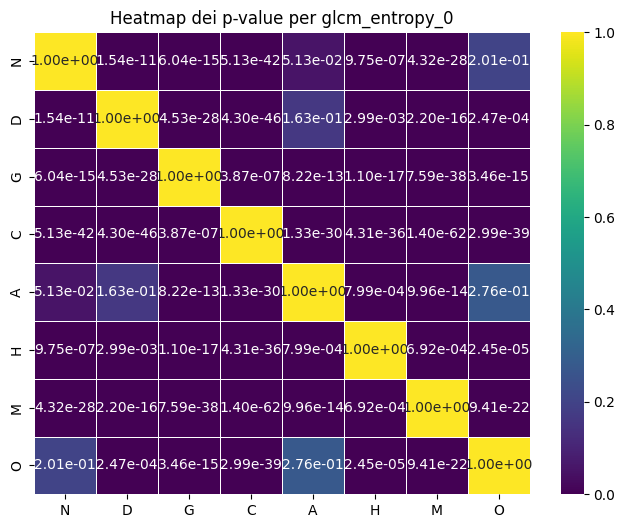

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


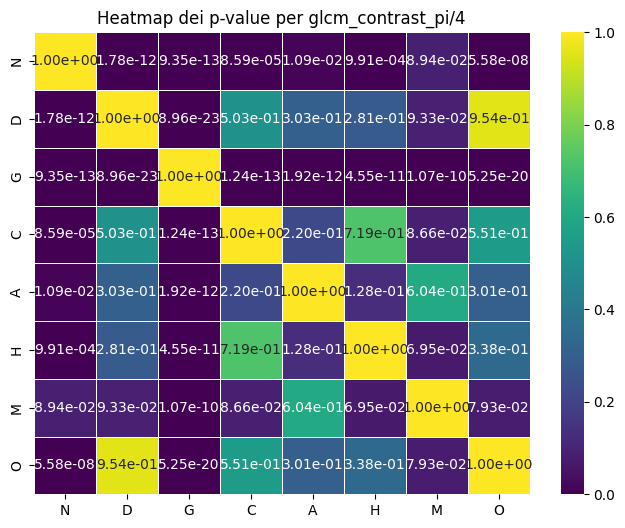

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


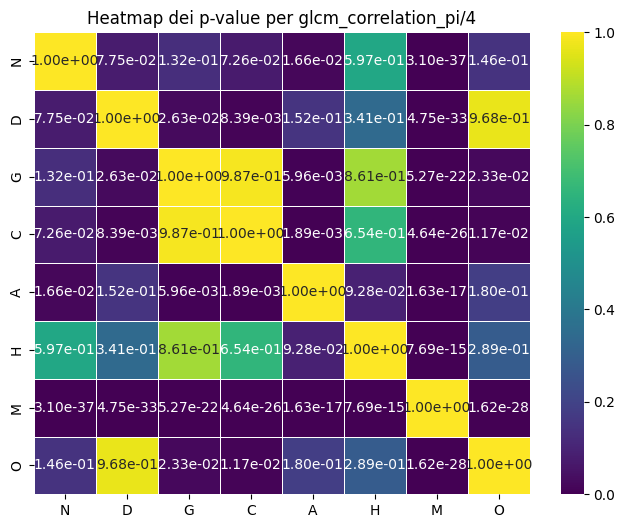

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


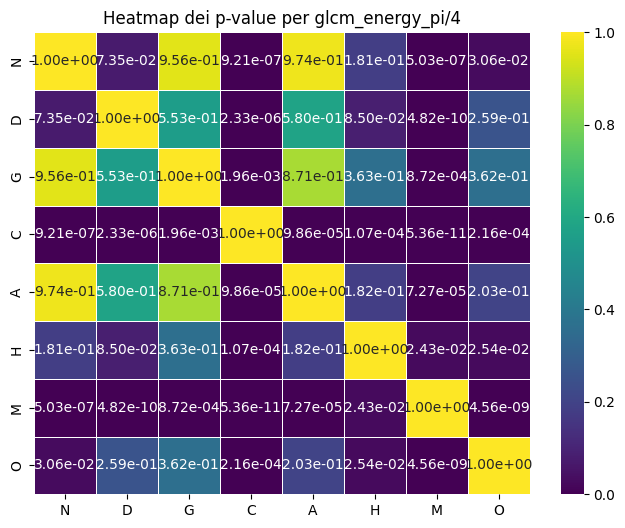

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


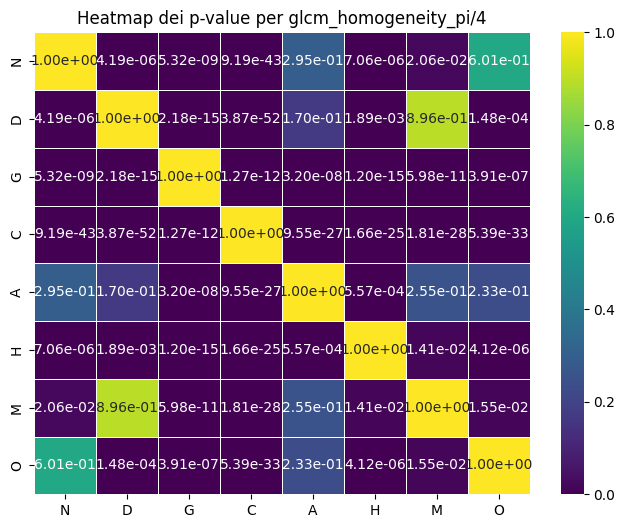

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


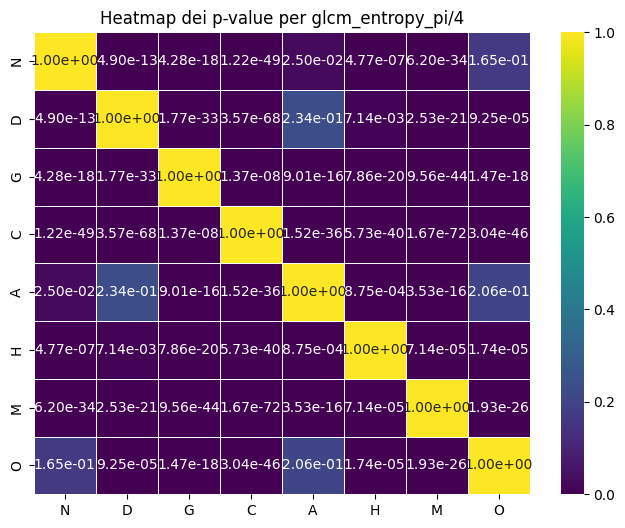

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


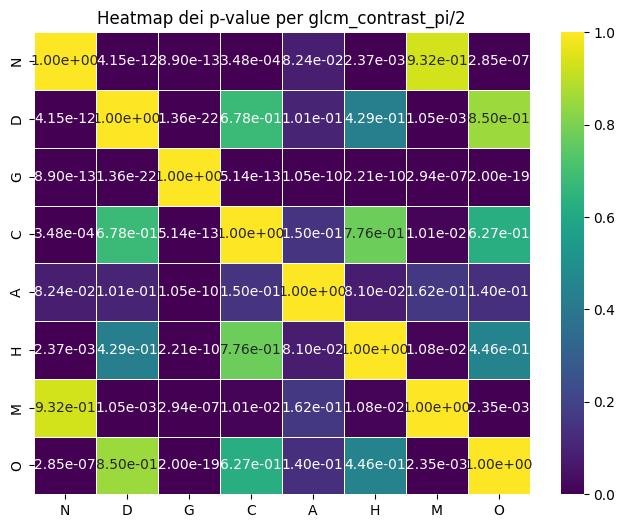

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


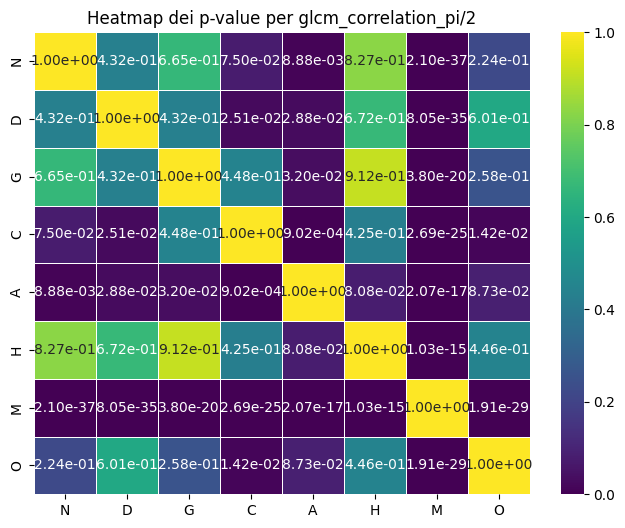

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


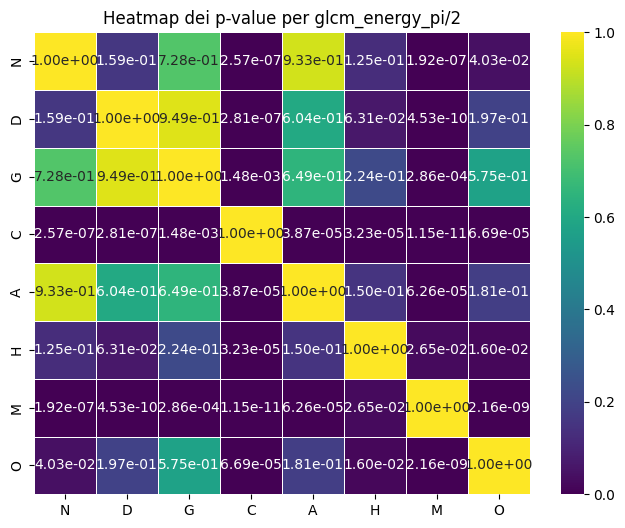

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


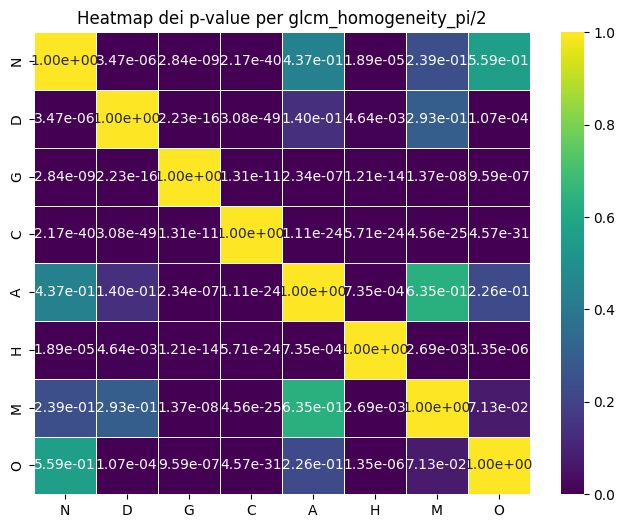

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


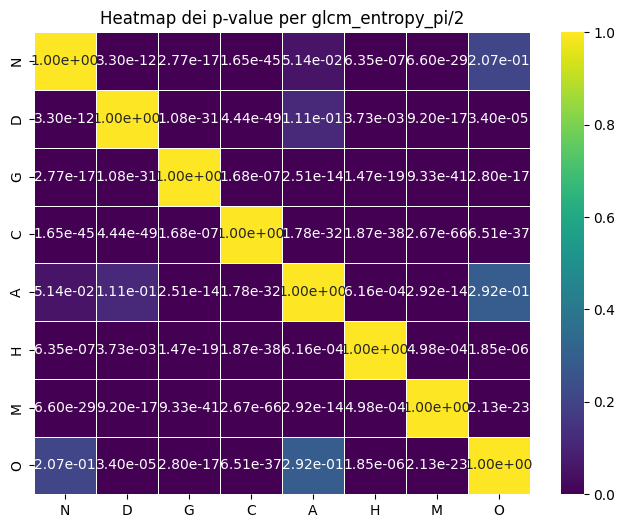

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


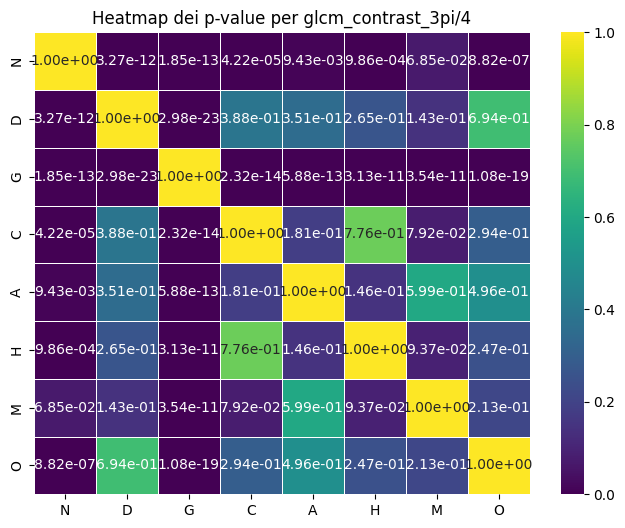

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


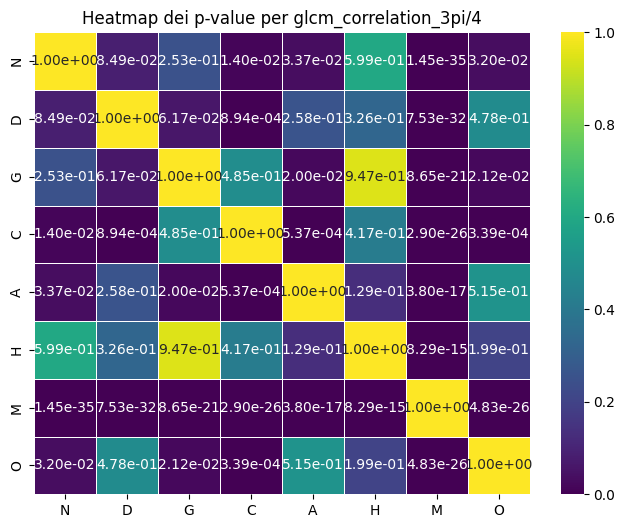

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


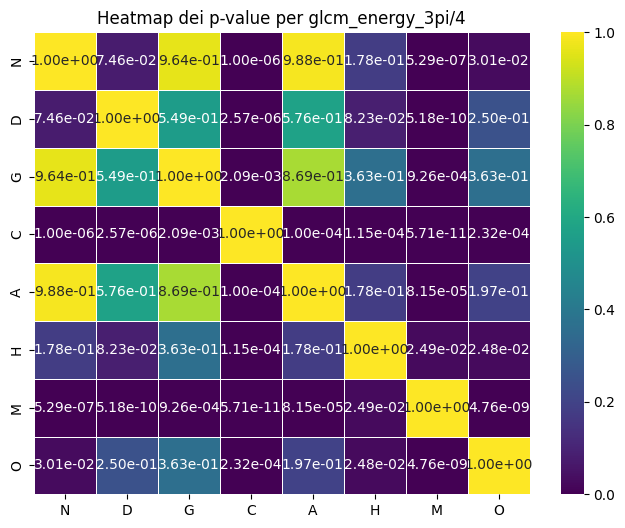

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


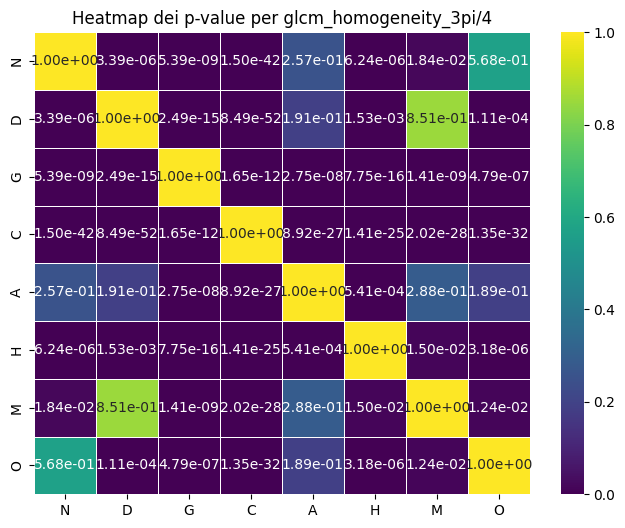

<ipython-input-10-0e35c59e8c6a>:73: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica


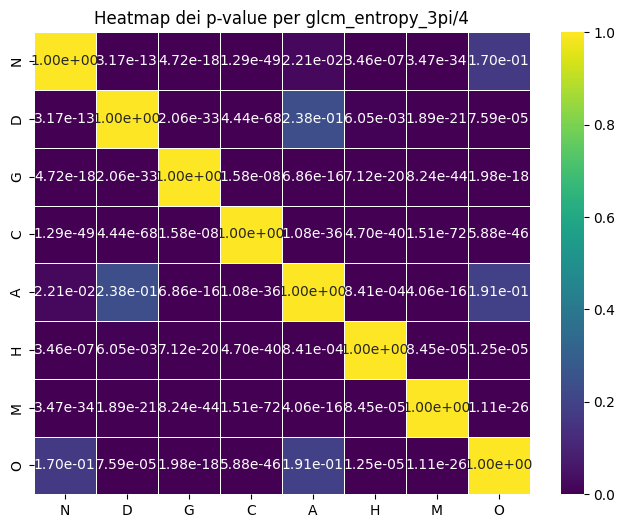

Numero di test T-test di Welch eseguiti: 89
Numero di test Mann-Whitney U eseguiti: 639


In [10]:
import itertools
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re
from statsmodels.stats.diagnostic import lilliefors
from tqdm import tqdm

# Otteniamo le feature significative dal test di Kruskal-Wallis
features_significative = df_KW[df_KW["Significative"] == "SI"]["Feature"].tolist()
class_names = list(df_dict.keys())

# Conta il numero di test eseguiti
welch_count, mannwhitney_count = 0, 0

# Iteriamo su ogni feature significativa
for feature in features_significative:
    results_pairwise = []  # Lista per salvare i risultati per ogni feature

    # Creiamo una matrice vuota per memorizzare i p-value
    p_value_matrix = pd.DataFrame(index=class_names, columns=class_names, dtype=float)

    # Otteniamo tutte le combinazioni di classi per ogni feature
    combinations = itertools.combinations(class_names, 2)

    for class_1, class_2 in combinations:
        class_1_data = df_dict[class_1][feature].dropna()
        class_2_data = df_dict[class_2][feature].dropna()

        # Verifica la normalità con il test di Lilliefors
        normal_test_class_1 = lilliefors_results_dict[class_1].loc[
            lilliefors_results_dict[class_1]["Feature"] == feature, "P-Value"
        ].values[0] >= alpha

        normal_test_class_2 = lilliefors_results_dict[class_2].loc[
            lilliefors_results_dict[class_2]["Feature"] == feature, "P-Value"
        ].values[0] >= alpha

        # Se entrambe le distribuzioni sono normali allora usa il T-test di Welch
        if normal_test_class_1 and normal_test_class_2:
            stat, p_value = stats.ttest_ind(class_1_data, class_2_data, equal_var=False)
            test_used = "T-test di Welch"
            welch_count += 1
        # Altrimenti usa il test di Mann-Whitney U
        else:
            stat, p_value = stats.mannwhitneyu(class_1_data, class_2_data, alternative='two-sided')
            test_used = "Mann-Whitney U"
            mannwhitney_count += 1

        # Salviamo il p-value nella matrice
        p_value_matrix.loc[class_1, class_2] = p_value
        p_value_matrix.loc[class_2, class_1] = p_value

        # Salviamo i dettagli nel CSV
        results_pairwise.append({
            "Feature": feature,
            "Classi Confrontate": f"{class_1} vs {class_2}",
            "Test Usato": test_used,
            "Statistica": f"{stat:.4f}",
            "P-Value": f"{p_value:.2e}"
        })

    # Riempie la diagonale con 1.000 (p-value massimo possibile)
    for c in class_names:
        p_value_matrix.loc[c, c] = 1.000

    # Creiamo la heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        p_value_matrix.astype(float),
        annot=p_value_matrix.applymap(lambda x: f"{x:.2e}"),  # Notazione scientifica
        cmap="viridis",
        fmt="",
        linewidths=0.5,
        cbar=True
    )
    plt.title(f"Heatmap dei p-value per {feature}")

    # Pulizia del nome della feature per evitare errori nei file
    safe_feature_name = re.sub(r"[^\w\-_]", "_", feature)

    # Salvataggio dell'immagine
    plt.savefig(f"heatmap_{safe_feature_name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Salva il DataFrame CSV con dettagli di test
    df_results = pd.DataFrame(results_pairwise)
    df_results.to_csv(f"test_results_{safe_feature_name}.csv", encoding="utf-8", index=False)

# Output dei conteggi dei test
print(f"Numero di test T-test di Welch eseguiti: {welch_count}")
print(f"Numero di test Mann-Whitney U eseguiti: {mannwhitney_count}")



In [11]:
import numpy as np

# Funzione per calcolare la Pooled Standard Deviation
def pooled_std(data1, data2):
    n1 = len(data1)
    n2 = len(data2)

    s1 = np.std(data1, ddof=1)  # Deviazione standard per data1
    s2 = np.std(data2, ddof=1)  # Deviazione standard per data2

    # Calcolo della Pooled Standard Deviation
    pooled = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
    return pooled

# Seleziona i dati della feature GLCM_energy_0 per ciascuna classe
glcm_contrast_D = df_dict['D']['glcm_contrast_pi/4'].dropna()
glcm_contrast_G = df_dict['G']['glcm_contrast_pi/4'].dropna()
glcm_contrast_N = df_dict['N']['glcm_contrast_pi/4'].dropna()
glcm_contrast_A = df_dict['A']['glcm_contrast_pi/4'].dropna()

# Calcola la mediana per ciascuna classe
median_D = np.median(glcm_contrast_D)
median_G = np.median(glcm_contrast_G)
median_N = np.median(glcm_contrast_N)
median_A = np.median(glcm_contrast_A)

# Stampa le mediane
print(f"Mediana della classe D: {median_D}")
print(f"Mediana della classe G: {median_G}")
print(f"Mediana della classe N: {median_N}")
print(f"Mediana della classe A: {median_A}")

# Calcola la Pooled Standard Deviation per le coppie di classi richieste
pooled_D_G = pooled_std(glcm_contrast_D, glcm_contrast_G)
pooled_N_A = pooled_std(glcm_contrast_N, glcm_contrast_A)
pooled_D_A = pooled_std(glcm_contrast_D, glcm_contrast_A)

# Stampa i risultati della Pooled Standard Deviation
print(f"Pooled Standard Deviation tra la classe D e G: {pooled_D_G}")
print(f"Pooled Standard Deviation tra la classe N e A: {pooled_N_A}")
print(f"Pooled Standard Deviation tra la classe D e A: {pooled_D_A}")



Mediana della classe D: 62.05119082724101
Mediana della classe G: 40.9545364026639
Mediana della classe N: 52.95590932939136
Mediana della classe A: 58.973527598316494
Pooled Standard Deviation tra la classe D e G: 44.89716276086482
Pooled Standard Deviation tra la classe N e A: 42.03386742537764
Pooled Standard Deviation tra la classe D e A: 45.016255563544334


<ipython-input-12-ba0d0f76d294>:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Classe", y="Valore", data=df_boxplot, palette="Set2", width=0.6, showfliers=True)


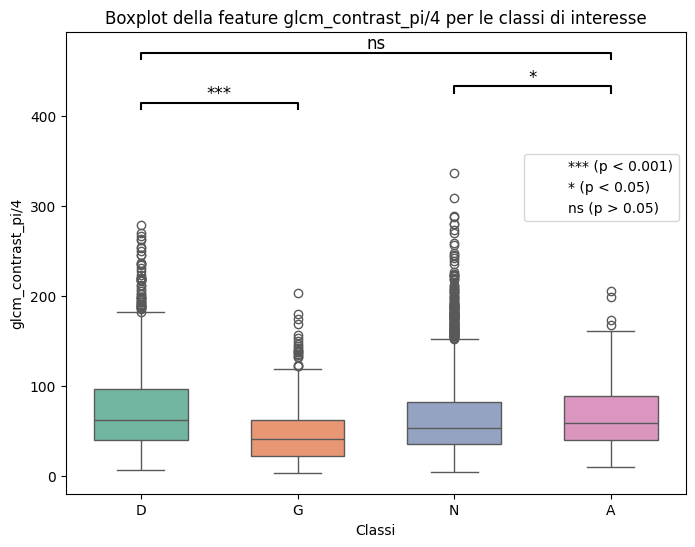

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

# Estrai i dati della feature "glcm_contrast_pi/4" per le classi di interesse
feature_name = "glcm_contrast_pi/4"

D_data = df_dict["D"][feature_name].dropna()
G_data = df_dict["G"][feature_name].dropna()
N_data = df_dict["N"][feature_name].dropna()
A_data = df_dict["A"][feature_name].dropna()

# Creazione del DataFrame per il boxplot
df_boxplot = pd.DataFrame({
    "Valore": np.concatenate([D_data, G_data, N_data, A_data]),
    "Classe": (["D"] * len(D_data)) + (["G"] * len(G_data)) +
              (["N"] * len(N_data)) + (["A"] * len(A_data))
})

# Creazione del boxplot con gli outliers visibili
plt.figure(figsize=(8, 6))
ax = sns.boxplot(x="Classe", y="Valore", data=df_boxplot, palette="Set2", width=0.6, showfliers=True)

plt.ylabel("glcm_contrast_pi/4")
plt.xlabel("Classi")
plt.title("Boxplot della feature glcm_contrast_pi/4 per le classi di interesse")

# Test statistici tra coppie di classi e aggiunta degli asterischi
comparisons = [("D", "G"), ("N", "A"), ("D", "A")]
y_max = df_boxplot["Valore"].max() * 1.1

# Definiamo delle altezze diverse per ogni confronto
heights = [y_max + 0.10 * y_max, y_max + 0.15 * y_max, y_max + 0.25 * y_max]

for i, (class1, class2) in enumerate(comparisons):
    data1 = df_boxplot[df_boxplot["Classe"] == class1]["Valore"]
    data2 = df_boxplot[df_boxplot["Classe"] == class2]["Valore"]

    # Test di Mann-Whitney U
    stat, p_value = mannwhitneyu(data1, data2, alternative="two-sided")

    # Determina il numero di asterischi in base al p-value
    if p_value < 0.001:
        stars = "***"
    elif p_value < 0.05:
        stars = "*"
    elif p_value > 0.05:
        stars = "ns"

    # Posizionamento degli asterischi e p-value nel grafico
    x1, x2 = ["D", "G", "N", "A"].index(class1), ["D", "G", "N", "A"].index(class2)

    # Linea continua per i confronti
    plt.plot([x1, x1, x2, x2], [heights[i], heights[i] + 0.02 * y_max, heights[i] + 0.02 * y_max, heights[i]],
             lw=1.5, color="black")

    # Asterischi nella parte superiore
    plt.text((x1 + x2) / 2, heights[i] + 0.02 * y_max, stars, ha="center", va="bottom", fontsize=12)

# Aggiunta della legenda
legend_elements = [
    Line2D([0], [0], color='white', lw=0, label="*** (p < 0.001)"),
    Line2D([0], [0], color='white', lw=0, label="* (p < 0.05)"),
    Line2D([0], [0], color='white', lw=0, label="ns (p > 0.05)")]

# Posiziona la legenda
plt.legend(handles=legend_elements, loc="upper right", fontsize=10, bbox_to_anchor=(1, 0.75))
plt.savefig(f"Box_plot_glcm_contrast_pi_4.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()



In [13]:
# Calcolo dei momenti di primo, secondo e terzo ordine

import numpy as np
import pandas as pd
from scipy.stats import skew

# Creazione di un dizionario per immagazzinare le statistiche
stats_dict = {}

# Itera sulle classi e calcola le statistiche richieste
for class_label in ["D", "G", "N", "A"]:
    data = df_dict[class_label]["glcm_contrast_pi/4"].dropna()

    # Calcola le statistiche
    mean_value = np.mean(data)
    variance_value = np.var(data, ddof=1)  # ddof=1 per stimatore corretto (varianza campionaria)
    skewness_value = skew(data, bias=False)  # bias=False per una stima più accurata

    # Salva i risultati nel dizionario
    stats_dict[class_label] = {
        "Media": mean_value,
        "Varianza": variance_value,
        "Skewness": skewness_value
    }

# Converti il dizionario in un DataFrame per una visualizzazione più chiara
df_stats = pd.DataFrame.from_dict(stats_dict, orient="index")

# Stampa i risultati
print(df_stats)


       Media     Varianza  Skewness
D  73.376021  2127.871621  1.284364
G  48.795749  1379.108407  1.497514
N  63.905170  1799.633147  1.656646
A  67.821365  1411.507690  0.985831
